In [ ]:
import numpy as np
import pandas as pd


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
customers = pd.read_csv('/content/drive/MyDrive/customers.csv')
products = pd.read_csv('/content/drive/MyDrive/products.csv')
orders = pd.read_csv('/content/drive/MyDrive/orders.csv')
order_items = pd.read_csv('/content/drive/MyDrive/order_items.csv')
returns = pd.read_csv('/content/drive/MyDrive/returns.csv')

In [ ]:
print(customers.shape)
print(products.shape)
print(orders.shape)
print(order_items.shape)
print(returns.shape)

(1215, 9)
(1112, 8)
(2022, 9)
(3535, 7)
(1120, 7)


In [ ]:
print(customers.columns.tolist())
print(products.columns.tolist())
print(orders.columns.tolist())
print(order_items.columns.tolist())
print(returns.columns.tolist())

['CustomerID', 'Name', 'Email', 'SignupDate', 'City', 'State', 'Country', 'Gender', 'Age']
['ProductID', 'ProductName', 'Category', 'Subcategory', 'Price', 'Cost', 'LaunchDate', 'Brand']
['Orderid', 'CustomerId', 'OrderDate', 'ShippingDate', 'OrderStatus', 'PaymentMode', 'TotalAmount', 'Discount', 'ShippingFee']
['OrderitemID', 'OrderID', 'ProductId', 'Quantity', 'Unitprice', 'Discount', 'TotalPrice']
['ReturnId', 'OrderId', 'ProductId', 'ReturnDate', 'Reason', 'RefundAmount', 'Status']


In [ ]:
customers.dtypes

,0
CustomerID,object
Name,object
Email,object
SignupDate,object
City,object
State,object
Country,object
Gender,object
Age,float64


In [ ]:
customers['CustomerID'] = customers['CustomerID'].astype('string')

In [ ]:
customers['Name'] = customers['Name'].astype('string')

In [ ]:
customers['Email'] = customers['Email'].astype('string')

In [ ]:
customers['SignupDate'] = pd.to_datetime(customers['SignupDate'],format= 'mixed',errors='coerce')


In [ ]:
customers['City'] = customers['City'].astype('string')

In [ ]:
customers['State'] = customers['State'].astype('string')

In [ ]:
customers['Country'] = customers['Country'].astype('string')

In [ ]:
customers['Age'] = customers['Age'].astype('Int64')


In [ ]:
customers['Gender'] = customers['Gender'].astype('category')

In [ ]:
customers.dtypes

,0
CustomerID,string[python]
Name,string[python]
Email,string[python]
SignupDate,datetime64[ns]
City,string[python]
State,string[python]
Country,string[python]
Gender,category
Age,Int64


In [ ]:
customers.isnull().sum()

,0
CustomerID,0
Name,0
Email,36
SignupDate,10
City,8
State,0
Country,0
Gender,2
Age,28


In [ ]:
customers['Email'] = customers['Email'].fillna('unknown')

In [ ]:
customers['SignupDate'] =customers['SignupDate'].fillna('unknown')


In [ ]:
customers['City'] = customers['City'].fillna('unknown')

In [ ]:

customers['Gender'] = customers['Gender'].cat.add_categories('Unknown').fillna('Unknown')


In [ ]:
customers['Age'] = customers['Age'].fillna(customers['Age'].median())


In [ ]:
customers.isnull().sum()

,0
CustomerID,0
Name,0
Email,0
SignupDate,0
City,0
State,0
Country,0
Gender,0
Age,0


In [ ]:
customers.duplicated().sum()

np.int64(15)

In [ ]:
customers[customers['CustomerID'].duplicated(keep=False)]

,CustomerID,Name,Email,SignupDate,City,State,Country,Gender,Age
34,C10034,Nisha Rao,nisha.rao35@example.in,2023-04-20 00:00:00,Howrah,West Bengal,India,Male,18
51,C10051,Aditya Singh,aditya.singh52@gmail.com,2022-10-29 00:00:00,Pune,Maharashtra,India,Female,24
140,C10140,Meera Patel,meera.patel141@outlook.com,2023-11-01 00:00:00,Nagpur,Maharashtra,India,Female,57
228,C10228,Ananya Gupta,ananya.gupta229@gmail.com,2022-09-02 00:00:00,Nagpur,Maharashtra,India,Male,18
298,C10298,Nisha Gupta,nisha.gupta299@gmail.com,2025-07-27 00:00:00,Mysuru,Karnataka,India,Male,49
360,C10360,Rahul Joshi,unknown,2025-04-02 00:00:00,Nagpur,Maharashtra,India,Prefer not to say,29
671,C10671,Rohan Kumar,rohan.kumar672@gmail.com,2022-12-16 00:00:00,Kanpur,Uttar Pradesh,India,Prefer not to say,41
696,C10696,Aarav Nair,aarav.nair697@gmail.com,2021-05-21 00:00:00,Howrah,West Bengal,India,Non-binary,24
743,C10743,Aisha Shetty,aisha.shetty744@outlook.com,2025-06-16 00:00:00,New Delhi,Delhi,India,Male,21
765,C10765,Aarav Sharma,aarav.sharma766@gmail.com,2025-08-25 00:00:00,Lucknow,Uttar Pradesh,India,Female,49


In [ ]:

customers = customers.drop_duplicates(subset=['CustomerID'],keep='first')

In [ ]:
customers.duplicated().sum()

np.int64(0)

In [ ]:
products.dtypes

,0
ProductID,object
ProductName,object
Category,object
Subcategory,object
Price,float64
Cost,float64
LaunchDate,object
Brand,object


In [ ]:
products['LaunchDate'] = pd.to_datetime(products['LaunchDate'],format='mixed',errors='coerce')

In [ ]:
products['Category'] = products['Category'].astype('category')

In [ ]:
products['Subcategory'] = products['Subcategory'].astype('category')

In [ ]:
products['Brand'] = products['Brand'].astype('category')

In [ ]:
products.isnull().sum()

,0
ProductID,0
ProductName,8
Category,0
Subcategory,5
Price,0
Cost,0
LaunchDate,12
Brand,8


In [ ]:
products['ProductName'] = products['ProductName'].fillna('unknown')

In [ ]:
products['Subcategory'] = products['Subcategory'].cat.add_categories('Unknown').fillna('Unknown')

checking total records and missing dates

In [ ]:
print("Total record: ",len(products))
print("Missing Dates",products['LaunchDate'].isnull().sum())
print("Missing percentage:",products['LaunchDate'].isnull().mean()*100)

Total record:  1112
Missing Dates 12
Missing percentage: 1.079136690647482


In [ ]:
products['LaunchDate'] = products['LaunchDate'].fillna('unknown')

In [ ]:
products['Brand'] = products['Brand'].cat.add_categories('Unknown').fillna('Unknown')

In [ ]:
products.isnull().sum()

,0
ProductID,0
ProductName,0
Category,0
Subcategory,0
Price,0
Cost,0
LaunchDate,0
Brand,0


In [ ]:
products.duplicated().sum()

np.int64(12)

In [ ]:
products = products.drop_duplicates(subset=['ProductID'],keep='first')

In [ ]:
products['ProductID'].duplicated().sum()

np.int64(0)

In [ ]:
products.duplicated().sum()

np.int64(0)

In [ ]:
order_items.dtypes

,0
OrderitemID,object
OrderID,object
ProductId,object
Quantity,int64
Unitprice,float64
Discount,float64
TotalPrice,float64


In [ ]:
order_items['OrderitemID'] = order_items['OrderitemID'].astype('string')

In [ ]:
order_items['OrderID'] = order_items['OrderID'].astype('string')

In [ ]:
order_items['ProductId'] = order_items['ProductId'].astype('string')

In [ ]:
order_items.dtypes

,0
OrderitemID,string[python]
OrderID,string[python]
ProductId,string[python]
Quantity,int64
Unitprice,float64
Discount,float64
TotalPrice,float64


In [ ]:
order_items.isnull().sum()

,0
OrderitemID,0
OrderID,0
ProductId,13
Quantity,0
Unitprice,0
Discount,15
TotalPrice,0


In [ ]:
order_items[order_items['Discount'].isnull()]

,OrderitemID,OrderID,ProductId,Quantity,Unitprice,Discount,TotalPrice
112,OI800112,O500963,P20895,4,1926.63,NaN,6550.54
570,OI800570,O501530,P20392,4,206.31,NaN,825.24
649,OI800649,O500676,P20618,1,1449.25,NaN,1159.40
652,OI800652,O500324,P20110,2,1438.66,NaN,2877.32
729,OI800729,O500512,P21014,6,3013.04,NaN,18078.24
1249,OI801249,O500791,P20937,5,1227.63,NaN,4910.52
1278,OI801278,O500494,P20152,4,970.44,NaN,3299.50
1597,OI801597,O500175,P20708,4,3475.67,NaN,13902.68
1850,OI801850,O501400,P20658,1,3866.98,NaN,3866.98
2220,OI802220,O501690,P20581,1,757.51,NaN,681.76


In [ ]:
order_items['Discount'].describe()

,Discount
count,3520.000000
mean,10.180398
std,15.252078
min,-15.000000
25%,0.000000
50%,5.000000
75%,20.000000
max,250.000000


In [ ]:
order_items[order_items['Discount'] < 0]

,OrderitemID,OrderID,ProductId,Quantity,Unitprice,Discount,TotalPrice
75,OI800075,O501476,P20534,2,3752.26,-15.0,7504.52
235,OI800235,O500773,P20733,5,327.53,-15.0,1473.88
337,OI800337,O501787,P20823,10,3466.27,-15.0,32929.56
603,OI800603,O500472,P21091,10,676.44,-15.0,6764.40
829,OI800829,O500206,P20440,5,370.13,-15.0,1387.99
976,OI800976,O500673,P20704,4,2179.81,-15.0,6539.43
1389,OI801389,O500397,P20706,4,4177.46,-15.0,16709.84
2240,OI802240,O500848,P20598,5,835.46,-15.0,4177.30
3079,OI803079,O501680,P20354,10,935.74,-15.0,7953.79


In [ ]:
order_items[order_items['Discount'] >100]

,OrderitemID,OrderID,ProductId,Quantity,Unitprice,Discount,TotalPrice
8,OI800008,O501459,P20512,2,3134.11,110.0,5014.58
149,OI800149,O501416,P20185,5,813.59,110.0,4067.95
203,OI800203,O500800,P20025,10,548.33,250.0,4112.48
207,OI800207,O501141,P20595,1,2039.92,110.0,2039.92
650,OI800650,O501364,P20115,10,0.00,110.0,0.00
780,OI800780,O501377,P20692,2,1374.36,150.0,2336.41
801,OI800801,O500434,P20523,1,1196.58,110.0,897.43
811,OI800811,O501985,P20114,2,2708.20,110.0,5416.40
1032,OI801032,O500126,P20764,2,576.15,110.0,979.45
1199,OI801199,O500064,P20556,1,241.68,150.0,241.68


In [ ]:
order_items.loc[
    (order_items['Discount'] < 0) |
    (order_items['Discount'] > 100),
    'Discount'
] = np.nan

In [ ]:
order_items['Discount'].isnull().sum()

np.int64(43)

In [ ]:
print("Negative:", (order_items['Discount'] < 0).sum())
print("Above 100:", (order_items['Discount'] > 100).sum())
print("Missing:", order_items['Discount'].isnull().sum())

Negative: 0
Above 100: 0
Missing: 43


In [ ]:
invalid = (
    (order_items['Discount'] < 0) |
    (order_items['Discount'] > 100)
)

order_items.loc[invalid, 'Discount'] = (
    1 - order_items.loc[invalid, 'TotalPrice'] /
    (order_items.loc[invalid, 'Quantity'] *
     order_items.loc[invalid, 'Unitprice'])
) * 100

In [ ]:
order_items['Discount'].value_counts(dropna=False).sort_index()

,count
Discount,
0.0,1313
5.0,441
10.0,424
15.0,430
20.0,423
25.0,461
NaN,43


Discount cannot be negative or greater than 100 as this discount column is treated in percentage now since we verified totalPrice follows the discount percentage formula, we can recover those 28 values

In [ ]:
print("Missing values:",order_items['Discount'].isnull().sum())
print("Negative values:", (order_items['Discount'] < 0).sum())
print("Above 100 values:", (order_items['Discount'] > 100).sum())

Missing values: 43
Negative values: 0
Above 100 values: 0


In [ ]:
order_items = pd.read_csv('/content/drive/MyDrive/order_items.csv')

In [ ]:
invalid = (
    (order_items['Discount'] < 0) |
    (order_items['Discount'] > 100)
)

In [ ]:
order_items.loc[invalid, 'Discount'] = (
    1 - order_items.loc[invalid, 'TotalPrice'] /
    (order_items.loc[invalid, 'Quantity'] *
     order_items.loc[invalid, 'Unitprice'])
) * 100

In [ ]:
print(order_items['Discount'].isnull().sum())
print(order_items['Discount'].value_counts().sort_index())

16
Discount
0.000000e+00    1322
1.110223e-14       3
4.999864e+00       1
5.000000e+00     441
5.000014e+00       1
1.000000e+01     424
1.000031e+01       1
1.500000e+01     430
1.500000e+01       1
1.500007e+01       1
1.500043e+01       1
1.999990e+01       1
1.999994e+01       1
2.000000e+01     423
2.499923e+01       1
2.499986e+01       1
2.499989e+01       1
2.499991e+01       1
2.500000e+01     462
2.500042e+01       1
2.500048e+01       1
Name: count, dtype: int64


In [ ]:
order_items['Discount'] = (
    np.round(order_items['Discount'] / 5) * 5
)

In [ ]:
order_items['Discount'].value_counts(dropna=False).sort_index()

,count
Discount,
0.0,1325
5.0,443
10.0,425
15.0,433
20.0,425
25.0,468
NaN,16


In [ ]:
print("Missing:", order_items['Discount'].isnull().sum())
print("Negative:", (order_items['Discount'] < 0).sum())
print("Above 100:", (order_items['Discount'] > 100).sum())

Missing: 16
Negative: 0
Above 100: 0


Identified 28 invalid discount values. Recovered 27 values using the verified TotalPrice formula. One value could not be recovered because Unitprice was zero. Retained 15 originally missing values.

In [ ]:
order_items.isnull().sum()

,0
OrderitemID,0
OrderID,0
ProductId,13
Quantity,0
Unitprice,0
Discount,16
TotalPrice,0


In [ ]:
order_items.describe()

,Quantity,Unitprice,Discount,TotalPrice
count,3535.000000,3535.000000,3519.000000,3.535000e+03
mean,6.710325,4546.448289,9.423132,1.483151e+04
std,53.500148,30317.978580,9.250309,1.172591e+05
min,-5.000000,-100.000000,0.000000,-9.990000e+02
25%,1.000000,735.420000,0.000000,1.418040e+03
50%,3.000000,1424.070000,5.000000,3.207410e+03
75%,5.000000,2652.060000,20.000000,7.493040e+03
max,999.000000,500000.000000,25.000000,2.500000e+06


In [ ]:
(order_items['Quantity']< 0).sum()

np.int64(18)

display negative records

In [ ]:
order_items[order_items['Quantity']< 0]

,OrderitemID,OrderID,ProductId,Quantity,Unitprice,Discount,TotalPrice
37,OI800037,O501701,P20213,-5,3999.74,0.0,7999.48
44,OI800044,O501370,P20305,-1,1825.68,0.0,1825.68
298,OI800298,O501705,P20651,-1,572.23,10.0,1545.02
673,OI800673,O501310,P20372,-1,5886.38,0.0,23545.52
739,OI800739,O500036,P20420,-1,4761.30,15.0,16188.42
754,OI800754,O501626,P20732,-1,5581.67,0.0,5581.67
824,OI800824,O500741,P20959,-1,973.98,0.0,973.98
1426,OI801426,O501045,P20927,-1,1957.49,0.0,3914.98
1588,OI801588,O500165,P20178,-5,2417.03,25.0,5438.32
1642,OI801642,O501084,P20637,-5,956.06,5.0,1816.51


checking zero quantity

In [ ]:
(order_items['Quantity']== 0).sum()

np.int64(3)

quantity distribution

In [ ]:
order_items['Quantity'].value_counts().sort_index()

,count
Quantity,
-5,8
-1,10
0,3
1,1025
2,713
3,336
4,370
5,382
6,312


In [ ]:
order_items[order_items['Quantity'] > 10]

,OrderitemID,OrderID,ProductId,Quantity,Unitprice,Discount,TotalPrice
39,OI800039,O501898,P20473,999,1325.05,15.0,2252.59
101,OI800101,O500551,P20569,150,2305.09,0.0,9220.36
166,OI800166,O501987,P20364,150,2021.01,0.0,10105.05
226,OI800226,O501980,P20481,999,521.33,0.0,1042.66
715,OI800715,O500315,P20593,999,761.77,15.0,647.50
1001,OI801001,O500530,P20375,999,2852.89,0.0,2852.89
1058,OI801058,O501562,P20316,999,3676.85,5.0,3493.01
1279,OI801279,O500743,P20300,150,3309.25,20.0,26474.00
1897,OI801897,O500348,P20512,999,3134.11,25.0,4701.16
1920,OI801920,O501171,P20236,150,8523.79,0.0,51142.74


bulk quantity is displayed might be error lets calculate the expected quantity based on the totalprice formula

In [ ]:
order_items['ExpectedQuantity'] = (
    order_items['TotalPrice'] /
    (order_items['Unitprice'] * (1 - order_items['Discount']/100))
)


In [ ]:
order_items[order_items['Quantity'] > 10][
    ['OrderitemID', 'Quantity', 'ExpectedQuantity',
     'Unitprice', 'Discount', 'TotalPrice']
]

,OrderitemID,Quantity,ExpectedQuantity,Unitprice,Discount,TotalPrice
39,OI800039,999,2.000004,1325.05,15.0,2252.59
101,OI800101,150,4.000000,2305.09,0.0,9220.36
166,OI800166,150,5.000000,2021.01,0.0,10105.05
226,OI800226,999,2.000000,521.33,0.0,1042.66
715,OI800715,999,0.999993,761.77,15.0,647.50
1001,OI801001,999,1.000000,2852.89,0.0,2852.89
1058,OI801058,999,1.000001,3676.85,5.0,3493.01
1279,OI801279,150,10.000000,3309.25,20.0,26474.00
1897,OI801897,999,1.999998,3134.11,25.0,4701.16
1920,OI801920,150,6.000000,8523.79,0.0,51142.74


camparing expected and recorded suspicious quantiy

In [ ]:
order_items['ExpectedQuantity'] = (
    order_items['ExpectedQuantity'].round()
)

In [ ]:
order_items.loc[
    order_items['Quantity'] > 10,
    ['OrderitemID', 'Quantity', 'ExpectedQuantity']
]

,OrderitemID,Quantity,ExpectedQuantity
39,OI800039,999,2.0
101,OI800101,150,4.0
166,OI800166,150,5.0
226,OI800226,999,2.0
715,OI800715,999,1.0
1001,OI801001,999,1.0
1058,OI801058,999,1.0
1279,OI801279,150,10.0
1897,OI801897,999,2.0
1920,OI801920,150,6.0


quantity column looks like in float converting to int

calculate consisitency

In [ ]:
order_items['ExpectedTotalPrice'] = (
    order_items['Quantity'] *
    order_items['Unitprice'] *
    (1 - order_items['Discount'] / 100)
)

In [ ]:
mask = order_items['Quantity'] > 10

order_items.loc[mask, 'Quantity'] = (
    order_items.loc[mask, 'ExpectedQuantity'].astype('Int64')
)

In [ ]:
order_items['Quantity'].value_counts().sort_index()

,count
Quantity,
-5,8
-1,10
0,3
1,1033
2,716
3,338
4,372
5,385
6,313


In [ ]:
order_items[order_items['Quantity'] > 10]

,OrderitemID,OrderID,ProductId,Quantity,Unitprice,Discount,TotalPrice,ExpectedQuantity,ExpectedTotalPrice


In [ ]:
order_items['Quantity'].dtype

dtype('int64')

quantity outlier detection

In [ ]:
Q1 = order_items['Quantity'].quantile(0.25)
Q3 = order_items['Quantity'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("lower: ",lower)
print("upper: ",upper)

lower:  -5.0
upper:  11.0


identity outlier

In [ ]:
quantity_outlier = order_items[
    (order_items['Quantity'] >= 0) & ((order_items['Quantity'] < lower) | (order_items['Quantity'] > upper))
]
print("Quantity outliers:",len(quantity_outlier))

Quantity outliers: 0


Display pf outlier

In [ ]:
quantity_outlier.head(10)

,OrderitemID,OrderID,ProductId,Quantity,Unitprice,Discount,TotalPrice,ExpectedQuantity,ExpectedTotalPrice


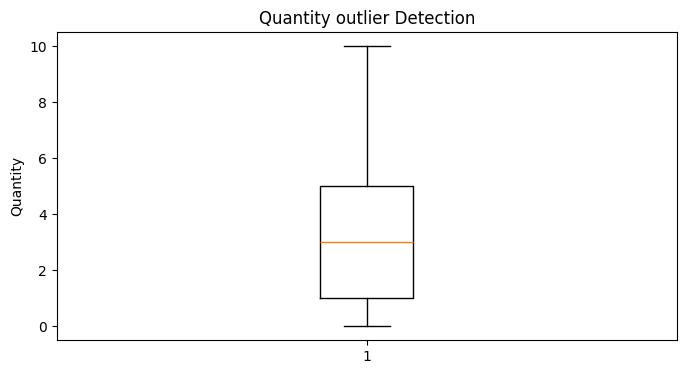

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,4))
plt.boxplot(order_items.loc[order_items['Quantity']>= 0,'Quantity'].dropna())
plt.title('Quantity outlier Detection')
plt.ylabel('Quantity')
plt.show()

unit price outlier detection

In [ ]:
order_items['Unitprice'].describe()

,Unitprice
count,3535.000000
mean,4546.448289
std,30317.978580
min,-100.000000
25%,735.420000
50%,1424.070000
75%,2652.060000
max,500000.000000


In [ ]:
Q1 = order_items['Unitprice'].quantile(0.25)
Q3 = order_items['Unitprice'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("lower limit:", lower)
print("upper limit:",upper)

lower limit: -2139.54
upper limit: 5527.02


In [ ]:
unitprice_outlier = order_items[
    (order_items['Unitprice'] < lower) |
    (order_items['Unitprice'] > upper)
]

print("UnitPrice outliers:", len(unitprice_outlier))

UnitPrice outliers: 212


In [ ]:
unitprice_outlier.head(10)

,OrderitemID,OrderID,ProductId,Quantity,Unitprice,Discount,TotalPrice,ExpectedQuantity,ExpectedTotalPrice
2,OI800002,O500370,P20448,2,19388.74,10.0,34899.73,2.0,34899.732
3,OI800003,O501688,P20076,3,7580.74,25.0,17056.67,3.0,17056.665
5,OI800005,O501043,P20540,6,7105.71,0.0,42634.26,6.0,42634.260
30,OI800030,O501662,P20524,1,99999.00,0.0,99999.00,1.0,99999.000
35,OI800035,O501855,P20236,4,8523.79,0.0,34095.16,4.0,34095.160
45,OI800045,O501180,P20784,1,5764.14,0.0,5764.14,1.0,5764.140
110,OI800110,O501229,P20943,1,5970.56,0.0,5970.56,1.0,5970.560
111,OI800111,O501608,P20418,10,11275.91,0.0,112759.10,10.0,112759.100
121,OI800121,O501873,P20943,1,5970.56,25.0,4477.92,1.0,4477.920
145,OI800145,O501928,P21048,2,500000.00,25.0,1567.34,0.0,750000.000


checking highest price

In [ ]:
order_items['Unitprice'].nlargest(20)

,Unitprice
145,500000.0
184,500000.0
459,500000.0
788,500000.0
1415,500000.0
1903,500000.0
2076,500000.0
2620,500000.0
2679,500000.0
2897,500000.0


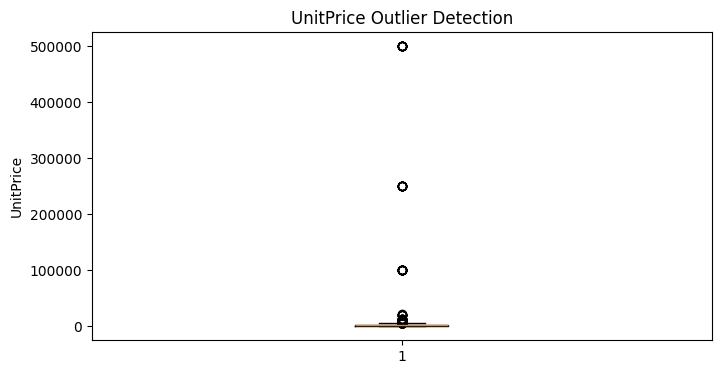

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.boxplot(order_items['Unitprice'].dropna())
plt.title('UnitPrice Outlier Detection')
plt.ylabel('UnitPrice')
plt.show()

Display high record

In [ ]:
order_items.nlargest(20, 'Unitprice')

,OrderitemID,OrderID,ProductId,Quantity,Unitprice,Discount,TotalPrice,ExpectedQuantity,ExpectedTotalPrice
145,OI800145,O501928,P21048,2,500000.0,25.0,1567.34,0.0,750000.0
184,OI800184,O501515,P20075,5,500000.0,20.0,2845.56,0.0,2000000.0
459,OI800459,O500024,P20752,1,500000.0,15.0,537.71,0.0,425000.0
788,OI800788,O501605,P20214,5,500000.0,0.0,4563.75,0.0,2500000.0
1415,OI801415,O501019,P20631,2,500000.0,0.0,3909.78,0.0,1000000.0
1903,OI801903,O500222,P21039,5,500000.0,0.0,9508.35,0.0,2500000.0
2076,OI802076,O501497,P20193,4,500000.0,25.0,-297.00,-0.0,1500000.0
2620,OI802620,O500743,P20520,2,500000.0,0.0,2253.52,0.0,1000000.0
2679,OI802679,O500348,P20757,1,500000.0,15.0,1135.96,0.0,425000.0
2897,OI802897,O501037,P20626,5,500000.0,0.0,7199.95,0.0,2500000.0


column with highesh valu

In [ ]:
unitprice_outlier.sort_values(
    by='Unitprice',
    ascending=False
)[['OrderitemID', 'ProductId', 'Quantity',
   'Unitprice', 'Discount', 'TotalPrice']].head(20)

,OrderitemID,ProductId,Quantity,Unitprice,Discount,TotalPrice
145,OI800145,P21048,2,500000.0,25.0,1567.34
184,OI800184,P20075,5,500000.0,20.0,2845.56
788,OI800788,P20214,5,500000.0,0.0,4563.75
459,OI800459,P20752,1,500000.0,15.0,537.71
2620,OI802620,P20520,2,500000.0,0.0,2253.52
2076,OI802076,P20193,4,500000.0,25.0,-297.00
2897,OI802897,P20626,5,500000.0,0.0,7199.95
2679,OI802679,P20757,1,500000.0,15.0,1135.96
1903,OI801903,P21039,5,500000.0,0.0,9508.35
1415,OI801415,P20631,2,500000.0,0.0,3909.78


price distribution

In [ ]:
order_items['Unitprice'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

,Unitprice
count,3535.000000
mean,4546.448289
std,30317.978580
min,-100.000000
25%,735.420000
50%,1424.070000
75%,2652.060000
90%,4437.880000
95%,5811.260000
99%,99999.000000


thr are suspicious unit price

In [ ]:
(order_items['Unitprice'] < 0).sum()

np.int64(26)

In [ ]:
order_items[order_items['Unitprice'] < 0]

,OrderitemID,OrderID,ProductId,Quantity,Unitprice,Discount,TotalPrice,ExpectedQuantity,ExpectedTotalPrice
50,OI800050,O500373,P20274,4,-99.0,5.0,-376.20,4.0,-376.20
107,OI800107,O501600,P20379,10,-99.0,20.0,-792.00,10.0,-792.00
143,OI800143,O500003,P20611,3,-99.0,0.0,-297.00,3.0,-297.00
695,OI800695,O501869,P20044,4,-99.0,25.0,-297.00,4.0,-297.00
879,OI800879,O501298,P20892,5,-99.0,20.0,-396.00,5.0,-396.00
1071,OI801071,O501631,P20044,2,-99.0,15.0,-168.30,2.0,-168.30
1096,OI801096,O501204,P20002,2,-100.0,15.0,2858.81,-34.0,-170.00
1115,OI801115,O501300,P20627,6,-100.0,15.0,6644.84,-78.0,-510.00
1432,OI801432,O501172,P20379,4,-99.0,0.0,-396.00,4.0,-396.00
1565,OI801565,O501130,P20997,4,-100.0,15.0,4413.03,-52.0,-340.00


checking distinct negative value

In [ ]:
order_items.loc[
    order_items['Unitprice'] < 0,
    'Unitprice'
].value_counts()

,count
Unitprice,
-99.0,18
-100.0,8


In [ ]:
order_items[order_items['Unitprice'] < 0][
    ['OrderitemID', 'Quantity', 'Unitprice',
     'Discount', 'TotalPrice']
]

,OrderitemID,Quantity,Unitprice,Discount,TotalPrice
50,OI800050,4,-99.0,5.0,-376.20
107,OI800107,10,-99.0,20.0,-792.00
143,OI800143,3,-99.0,0.0,-297.00
695,OI800695,4,-99.0,25.0,-297.00
879,OI800879,5,-99.0,20.0,-396.00
1071,OI801071,2,-99.0,15.0,-168.30
1096,OI801096,2,-100.0,15.0,2858.81
1115,OI801115,6,-100.0,15.0,6644.84
1432,OI801432,4,-99.0,0.0,-396.00
1565,OI801565,4,-100.0,15.0,4413.03


handle negative unit price

In [ ]:
order_items.loc[
    order_items['Unitprice'] < 0,
    'Unitprice'
] = np.nan

In [ ]:
print("Negative prices:",
      (order_items['Unitprice'] < 0).sum())

print("Missing prices:",
      order_items['Unitprice'].isnull().sum())

Negative prices: 0
Missing prices: 26


In [ ]:
order_items[order_items['Unitprice'] > 10000][
    ['OrderitemID', 'Quantity', 'Unitprice',
     'Discount', 'TotalPrice']
]

,OrderitemID,Quantity,Unitprice,Discount,TotalPrice
2,OI800002,2,19388.74,10.0,34899.73
30,OI800030,1,99999.00,0.0,99999.00
111,OI800111,10,11275.91,0.0,112759.10
145,OI800145,2,500000.00,25.0,1567.34
184,OI800184,5,500000.00,20.0,2845.56
...,...,...,...,...,...
3020,OI803020,10,250000.00,25.0,1875000.00
3158,OI803158,6,19388.74,0.0,116332.44
3333,OI803333,1,99999.00,25.0,807.18
3378,OI803378,1,10636.98,0.0,10636.98


In [ ]:
high_price = order_items[
    order_items['Unitprice'] > 10000
].copy()

high_price['ExpectedTotal'] = (
    high_price['Quantity'] *
    high_price['Unitprice'] *
    (1 - high_price['Discount'] / 100)
)

high_price['Difference'] = (
    high_price['TotalPrice'] -
    high_price['ExpectedTotal']
)

display inconsistent record

In [ ]:
high_price[
    abs(high_price['Difference']) > 0.02
][
    ['OrderitemID', 'Quantity', 'Unitprice',
     'Discount', 'TotalPrice',
     'ExpectedTotal', 'Difference']
]

,OrderitemID,Quantity,Unitprice,Discount,TotalPrice,ExpectedTotal,Difference
145,OI800145,2,500000.0,25.0,1567.34,750000.00,-748432.66
184,OI800184,5,500000.0,20.0,2845.56,2000000.00,-1997154.44
333,OI800333,5,99999.0,20.0,6461.36,399996.00,-393534.64
459,OI800459,1,500000.0,15.0,537.71,425000.00,-424462.29
623,OI800623,5,99999.0,20.0,14653.20,399996.00,-385342.80
711,OI800711,1,99999.0,0.0,2042.81,99999.00,-97956.19
788,OI800788,5,500000.0,0.0,4563.75,2500000.00,-2495436.25
851,OI800851,1,99999.0,25.0,305.66,74999.25,-74693.59
1016,OI801016,2,99999.0,0.0,2500000.00,199998.00,2300002.00
1162,OI801162,2,99999.0,10.0,5011.24,179998.20,-174986.96


In [ ]:
high_price['IsMismatch'] = ~np.isclose(
    high_price['TotalPrice'],
    high_price['ExpectedTotal'],
    atol=0.02
)

print(high_price['IsMismatch'].value_counts())

IsMismatch
False    41
True     20
Name: count, dtype: int64


Observation:
Identified 212 statistical outliers in UnitPrice using the IQR method. Among the 61 records with UnitPrice above 10,000, 41 followed the verified pricing formula, while 20 showed inconsistencies and were flagged for further investigation."

In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2022 entries, 0 to 2021
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Orderid       2022 non-null   object 
 1   CustomerId    1983 non-null   object 
 2   OrderDate     2012 non-null   object 
 3   ShippingDate  1625 non-null   object 
 4   OrderStatus   2022 non-null   object 
 5   PaymentMode   2022 non-null   object 
 6   TotalAmount   2022 non-null   float64
 7   Discount      2022 non-null   float64
 8   ShippingFee   2022 non-null   float64
dtypes: float64(3), object(6)
memory usage: 142.3+ KB


In [ ]:
orders['Orderid'] = orders['Orderid'].astype('string')

In [ ]:
orders['CustomerId'] = orders['CustomerId'].astype('string')

In [ ]:
orders['OrderDate'] = pd.to_datetime(orders['OrderDate'],format='mixed',errors='coerce')

In [ ]:
orders['ShippingDate'] = pd.to_datetime(orders['ShippingDate'],format='mixed',errors='coerce')

In [ ]:
orders['OrderStatus'] = orders['OrderStatus'].astype('category')

In [ ]:
orders['PaymentMode'] = orders['PaymentMode'].astype('category')

In [ ]:
orders.dtypes

,0
Orderid,string[python]
CustomerId,string[python]
OrderDate,datetime64[ns]
ShippingDate,datetime64[ns]
OrderStatus,category
PaymentMode,category
TotalAmount,float64
Discount,float64
ShippingFee,float64


In [ ]:
orders.isnull().sum()

,0
Orderid,0
CustomerId,39
OrderDate,10
ShippingDate,397
OrderStatus,0
PaymentMode,0
TotalAmount,0
Discount,0
ShippingFee,0


In [ ]:
orders[orders['CustomerId'].isnull()]

,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee
54,O500054,<NA>,2024-03-16,NaT,Pending,Wallet,1213.15,15.0,40.0
77,O500077,<NA>,2023-10-07,2023-10-09,Delivered,Credit Card,1152.45,10.0,99.0
84,O500084,<NA>,2025-02-13,2025-02-14,Delivered,Cash on Delivery,3317.21,0.0,60.0
143,O500143,<NA>,2025-07-14,2025-07-16,Delivered,Net Banking,463.91,0.0,50.0
215,O500215,<NA>,2024-04-22,2024-04-25,Delivered,UPI,2703.08,20.0,120.0
230,O500230,<NA>,2023-12-03,2023-04-12,Delivered,Wallet,3414.07,0.0,120.0
316,O500316,<NA>,2025-01-29,NaT,Pending,Debit Card,3891.88,0.0,75.0
318,O500318,<NA>,2023-01-12,2023-12-05,Delivered,Debit Card,4679.62,0.0,99.0
354,O500354,<NA>,2025-08-13,2025-08-21,Delivered,Debit Card,914.51,0.0,0.0
371,O500371,<NA>,2023-11-14,2023-11-19,Shipped,UPI,760.24,15.0,99.0


In [ ]:
orders['CustomerId'].isnull().sum()

np.int64(39)

insghts:
Do not replace them with mean, median or an arbitrary ID. Customer IDs are identifiers, not numerical measurements.

In [ ]:
orders[orders['OrderDate'].isnull()]

,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee
124,O500124,C10094,NaT,2024-06-04,Delivered,upi,7963.35,30.0,60.0
409,O500409,C10583,NaT,2024-06-23,Delivered,Other,3824.79,15.0,0.0
1096,O501096,C10419,NaT,NaT,Processing,Cash on Delivery,396.83,30.0,0.0
1148,O501148,C10026,NaT,2023-03-16,Delivered,Credit Card,7483.28,25.0,0.0
1262,O501262,C10170,NaT,2024-01-09,Returned,Credit Card,930.08,15.0,50.0
1500,O501500,C10512,NaT,2024-05-20,Delivered,UPI,4668.95,0.0,75.0
1623,O501623,C10257,NaT,NaT,Processing,Wallet,5121.31,0.0,50.0
1670,O501670,C10431,NaT,2025-05-07,Delivered,Credit Card,531.89,0.0,0.0
1747,O501747,C10425,NaT,2025-04-13,Delivered,Cash on Delivery,0.00,0.0,60.0
1886,O501886,C10568,NaT,NaT,Processing,UPI,2461.38,30.0,120.0


we cannot replace the date with mean or median because date represents actual business events.


Investigating the shipping date.

In [ ]:
orders[orders['ShippingDate'].isnull()]['OrderStatus'].value_counts()

,count
OrderStatus,
Processing,163
Cancelled,145
Pending,82
DELIVERED,2
complete,2
In Transit,1
cancel,1
Unknown,1
Delivered,0


In [ ]:
orders['Orderid'].duplicated().sum()

np.int64(22)

In [ ]:
orders[
    orders['ShippingDate'].isnull() &
    (orders['OrderStatus'].isin(
        ['DELIVERED', 'complete', 'In Transit', 'Unknown']
    ))
]

,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee
128,O500128,C10070,2023-04-10,NaT,Unknown,Credit Card,2880.60,0.0,99.0
836,O500836,C10057,2025-05-11,NaT,complete,Cash on Delivery,1000.35,0.0,0.0
1063,O501063,C10419,2025-06-27,NaT,In Transit,Net Banking,6657.70,0.0,99.0
1471,O501471,C10200,2023-03-13,NaT,DELIVERED,Credit Card,1111.04,25.0,0.0
1666,O501666,C10850,2024-03-15,NaT,complete,Credit Card,9692.86,5.0,75.0
1956,O501956,C10129,2023-04-05,NaT,DELIVERED,UPI,1570.14,10.0,60.0


In [ ]:
orders['OrderStatus'].value_counts()

,count
OrderStatus,
Delivered,1317
Shipped,170
Processing,163
Cancelled,145
Returned,123
Pending,82
Unknown,5
complete,5
cancel,4


In [ ]:
orders[
    orders['ShippingDate']< orders['OrderDate']
]


,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee
34,O500034,C10987,2024-08-01,2024-01-14,Delivered,UPI,1657.22,15.0,40.0
40,O500040,C10945,2024-09-05,2024-05-17,Delivered,Credit Card,10746.63,15.0,75.0
82,O500082,C10554,2025-10-09,2025-09-17,Delivered,Credit Card,5849.86,10.0,120.0
98,O500098,C10583,2023-04-30,2023-03-05,Delivered,UPI,4254.54,0.0,999.0
114,O500114,C10790,2023-09-08,2023-08-11,Shipped,UPI,2737.31,25.0,120.0
...,...,...,...,...,...,...,...,...,...
1950,O501950,C10420,2024-10-09,2024-09-16,Delivered,Cash on Delivery,2091.22,15.0,99.0
1978,O501978,C10909,2023-03-31,2023-01-04,Delivered,Cash on Delivery,6342.91,5.0,50.0
1994,O501994,C10071,2023-01-26,2023-01-02,Delivered,UPI,3610.45,15.0,0.0
2007,O501868,C11065,2025-10-06,2025-09-10,Shipped,Credit Card,1294.11,20.0,75.0


In [ ]:
#lets count the records first
(orders['ShippingDate'] < orders['OrderDate']).sum()

np.int64(158)

In [ ]:
date_issue = orders[orders['OrderDate']< orders['ShippingDate']]
date_issue[['Orderid','OrderDate','ShippingDate','OrderStatus']]

,Orderid,OrderDate,ShippingDate,OrderStatus
0,O500000,2024-01-23,2024-01-28,Delivered
1,O500001,2024-09-03,2024-09-05,Shipped
2,O500002,2024-03-09,2024-03-16,Delivered
3,O500003,2024-12-14,2024-12-18,Shipped
4,O500004,2025-08-03,2025-10-03,Returned
...,...,...,...,...
2016,O501812,2024-04-22,2024-04-30,Delivered
2017,O500987,2025-04-08,2025-04-11,Delivered
2018,O501372,2024-01-06,2024-04-06,Delivered
2019,O500838,2023-07-11,2023-10-11,Delivered


normal sequency

In [ ]:
(orders['OrderDate']< orders['ShippingDate']).sum()

np.int64(1460)

incorrect sequency

In [ ]:
(orders['OrderDate']> orders['ShippingDate']).sum()

np.int64(158)

In [ ]:
(orders['ShippingDate'] == orders['OrderDate']).sum()

np.int64(0)

In [ ]:
date_issue = orders[
    orders['OrderDate'] > orders['ShippingDate']
]

date_issue[['Orderid', 'OrderDate',
            'ShippingDate', 'OrderStatus']].head(20)

,Orderid,OrderDate,ShippingDate,OrderStatus
34,O500034,2024-08-01,2024-01-14,Delivered
40,O500040,2024-09-05,2024-05-17,Delivered
82,O500082,2025-10-09,2025-09-17,Delivered
98,O500098,2023-04-30,2023-03-05,Delivered
114,O500114,2023-09-08,2023-08-11,Shipped
120,O500120,2023-04-02,2023-02-10,Delivered
132,O500132,2024-10-09,2024-09-16,Delivered
134,O500134,2025-10-01,2025-09-10,Shipped
136,O500136,2025-06-29,2025-05-07,Delivered
140,O500140,2025-05-25,2025-01-06,Delivered


In [ ]:
#cal shiiping date dif
orders['ShippingDelay'] = (
    orders['ShippingDate'] - orders['OrderDate']
).dt.days


In [ ]:
orders[orders['ShippingDelay'] < 0][
    ['Orderid', 'OrderDate', 'ShippingDate', 'ShippingDelay']
].head(20)

,Orderid,OrderDate,ShippingDate,ShippingDelay
34,O500034,2024-08-01,2024-01-14,-200.0
40,O500040,2024-09-05,2024-05-17,-111.0
82,O500082,2025-10-09,2025-09-17,-22.0
98,O500098,2023-04-30,2023-03-05,-56.0
114,O500114,2023-09-08,2023-08-11,-28.0
120,O500120,2023-04-02,2023-02-10,-51.0
132,O500132,2024-10-09,2024-09-16,-23.0
134,O500134,2025-10-01,2025-09-10,-21.0
136,O500136,2025-06-29,2025-05-07,-53.0
140,O500140,2025-05-25,2025-01-06,-139.0


In [ ]:
# Check incorrect records by order status
orders[orders['ShippingDelay'] < 0]['OrderStatus'].value_counts()

,count
OrderStatus,
Delivered,129
Shipped,21
Returned,7
Unknown,1
In Transit,0
DELIVERED,0
Cancelled,0
Processing,0
Pending,0


Handle incorrect dates

In [ ]:
orders['DateIssue'] = orders['ShippingDate'] < orders['OrderDate']

In [ ]:
orders['DateIssue'].value_counts()

,count
DateIssue,
False,1864
True,158


In [ ]:
#handle shipping delay
orders.loc[orders['DateIssue'], 'ShippingDelay'] = np.nan


In [ ]:
(orders['ShippingDelay'] < 0).sum()

np.int64(0)

In [ ]:
#count of duplicate
orders['Orderid'].duplicated().sum()

np.int64(22)

In [ ]:
#display duplicate record
orders[orders['Orderid'].duplicated(keep=False)].sort_values('Orderid')


,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee,ShippingDelay,DateIssue
167,O500167,C10777,2024-10-20,NaT,Pending,Wallet,1303.71,30.0,120.0,NaN,False
2012,O500167,C10777,2024-10-20,NaT,Pending,Wallet,1303.71,30.0,120.0,NaN,False
339,O500339,C10954,2023-02-22,NaT,Processing,UPI,1859.62,5.0,50.0,NaN,False
2015,O500339,C10954,2023-02-22,NaT,Processing,UPI,1859.62,5.0,50.0,NaN,False
800,O500800,C10835,2025-03-18,2025-03-25,Delivered,Credit Card,3397.34,10.0,75.0,7.0,False
2003,O500800,C10835,2025-03-18,2025-03-25,Delivered,Credit Card,3397.34,10.0,75.0,7.0,False
838,O500838,C11100,2023-07-11,2023-10-11,Delivered,Credit Card,3037.88,30.0,0.0,92.0,False
2019,O500838,C11100,2023-07-11,2023-10-11,Delivered,Credit Card,3037.88,30.0,0.0,92.0,False
871,O500871,C10952,2023-09-10,2023-09-13,Delivered,Credit Card,1189.81,0.0,50.0,3.0,False
2013,O500871,C10952,2023-09-10,2023-09-13,Delivered,Credit Card,1189.81,0.0,50.0,3.0,False


Check duplicate rows across all columns

In [ ]:
orders.duplicated().sum()

np.int64(22)

Verify whether all duplicate Order IDs are exact duplicates

In [ ]:
orders[orders['Orderid'].duplicated(keep=False)].sort_values('Orderid')

,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee,ShippingDelay,DateIssue
167,O500167,C10777,2024-10-20,NaT,Pending,Wallet,1303.71,30.0,120.0,NaN,False
2012,O500167,C10777,2024-10-20,NaT,Pending,Wallet,1303.71,30.0,120.0,NaN,False
339,O500339,C10954,2023-02-22,NaT,Processing,UPI,1859.62,5.0,50.0,NaN,False
2015,O500339,C10954,2023-02-22,NaT,Processing,UPI,1859.62,5.0,50.0,NaN,False
800,O500800,C10835,2025-03-18,2025-03-25,Delivered,Credit Card,3397.34,10.0,75.0,7.0,False
2003,O500800,C10835,2025-03-18,2025-03-25,Delivered,Credit Card,3397.34,10.0,75.0,7.0,False
838,O500838,C11100,2023-07-11,2023-10-11,Delivered,Credit Card,3037.88,30.0,0.0,92.0,False
2019,O500838,C11100,2023-07-11,2023-10-11,Delivered,Credit Card,3037.88,30.0,0.0,92.0,False
871,O500871,C10952,2023-09-10,2023-09-13,Delivered,Credit Card,1189.81,0.0,50.0,3.0,False
2013,O500871,C10952,2023-09-10,2023-09-13,Delivered,Credit Card,1189.81,0.0,50.0,3.0,False


In [ ]:
#remove duplicate
orders = orders.drop_duplicates(keep='first')

In [ ]:
print("Duplicate Order IDs:", orders['Orderid'].duplicated().sum())

print("Duplicate rows:", orders.duplicated().sum())

Duplicate Order IDs: 0
Duplicate rows: 0


In [ ]:
#checking negative values
orders[orders['TotalAmount']< 0]

,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee,ShippingDelay,DateIssue
429,O500429,C10623,2025-07-26,NaT,Cancelled,Net Banking,-250.0,0.0,50.0,NaN,False
884,O500884,C10611,2025-04-03,2025-06-04,Delivered,Debit Card,-250.0,10.0,50.0,62.0,False


In [ ]:
(orders['TotalAmount'] < 0).sum()

np.int64(2)

In [ ]:
#check zero values
(orders['TotalAmount'] == 0).sum()

np.int64(7)

In [ ]:
orders['TotalAmount'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

,TotalAmount
count,2.000000e+03
mean,8.531232e+03
std,8.011689e+04
min,-2.500000e+02
25%,1.166477e+03
50%,2.254865e+03
75%,4.022443e+03
90%,6.759400e+03
95%,9.622517e+03
99%,1.702349e+04


In [ ]:
#checking high values
orders[orders['TotalAmount'] > 10000][
    ['Orderid', 'OrderStatus', 'TotalAmount']
]

,Orderid,OrderStatus,TotalAmount
2,O500002,Delivered,11441.01
8,O500008,Processing,18301.07
39,O500039,Delivered,16175.23
40,O500040,Delivered,10746.63
48,O500048,Processing,10926.98
...,...,...,...
1853,O501853,Delivered,32365.09
1899,O501899,Delivered,15809.06
1941,O501941,Delivered,999999.00
1982,O501982,Returned,19105.73


observation: 999,999 is particularly suspicious, but we should investigate before treating it as an error.

In [ ]:
#Check TotalAmount outliers using IQR
Q1 = orders['TotalAmount'].quantile(0.25)
Q3 = orders['TotalAmount'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("lower:",lower)
print("upper:",upper)

lower: -3117.4700000000003
upper: 8306.39


In [ ]:
amount_outlier = orders[
    (orders['TotalAmount'] < lower) |
    (orders['TotalAmount'] > upper)
]

print("TotalAmount outliers:", len(amount_outlier))


TotalAmount outliers: 136


In [ ]:
amount_outlier[
    ['Orderid', 'OrderStatus', 'TotalAmount']
].sort_values('TotalAmount', ascending=False)

,Orderid,OrderStatus,TotalAmount
660,O500660,Delivered,1250000.00
1285,O501285,Delivered,1250000.00
1537,O501537,Delivered,1250000.00
1265,O501265,Delivered,1250000.00
346,O500346,Pending,1250000.00
...,...,...,...
1649,O501649,Delivered,8489.46
235,O500235,Cancelled,8452.90
1046,O501046,Returned,8451.80
672,O500672,Delivered,8414.39


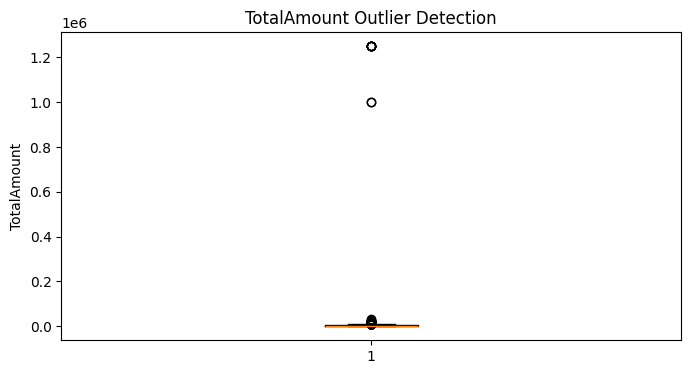

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.boxplot(orders['TotalAmount'].dropna())

plt.title('TotalAmount Outlier Detection')
plt.ylabel('TotalAmount')
plt.show()

In [ ]:
#investigating negative outliers
orders[orders['TotalAmount'] < 0][
    ['Orderid', 'OrderStatus', 'TotalAmount']
]

,Orderid,OrderStatus,TotalAmount
429,O500429,Cancelled,-250.0
884,O500884,Delivered,-250.0


In [ ]:
#investigating zero total amount
orders[orders['TotalAmount'] == 0][
    ['Orderid', 'OrderStatus', 'TotalAmount']
]

,Orderid,OrderStatus,TotalAmount
402,O500402,Delivered,0.0
658,O500658,Delivered,0.0
661,O500661,Delivered,0.0
860,O500860,Delivered,0.0
1310,O501310,Delivered,0.0
1650,O501650,Delivered,0.0
1747,O501747,Delivered,0.0


In [ ]:
#calculating outliers
Q1 = orders['TotalAmount'].quantile(0.25)
Q3 = orders['TotalAmount'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("lower:",lower)
print("upper:",upper)

lower: -3117.4700000000003
upper: 8306.39


In [ ]:
#outliers count
amount_outlier = orders[
    (orders['TotalAmount']<lower) | (orders['TotalAmount']> upper)
]
print("TotalAmount outliers:",len(amount_outlier))

TotalAmount outliers: 136


In [ ]:
#highest outliers
amount_outlier.sort_values(
    'TotalAmount',
    ascending=False
)[
    ['Orderid', 'OrderStatus', 'TotalAmount']
].head(20)

,Orderid,OrderStatus,TotalAmount
660,O500660,Delivered,1250000.00
1285,O501285,Delivered,1250000.00
1537,O501537,Delivered,1250000.00
1265,O501265,Delivered,1250000.00
346,O500346,Pending,1250000.00
756,O500756,Delivered,1250000.00
104,O500104,Cancelled,1250000.00
304,O500304,Returned,999999.00
1941,O501941,Delivered,999999.00
1853,O501853,Delivered,32365.09


In [ ]:
orders['TotalAmount'].value_counts().head(15)

,count
TotalAmount,
1250000.00,7
0.00,7
702.89,2
-250.00,2
1088.89,2
999999.00,2
658.66,1
1160.94,1
2551.44,1


In [ ]:
#high order values with thr status
orders[
    orders['TotalAmount'] >= 100000
][
    ['Orderid', 'OrderStatus', 'TotalAmount']
].sort_values('TotalAmount', ascending=False)

,Orderid,OrderStatus,TotalAmount
104,O500104,Cancelled,1250000.0
346,O500346,Pending,1250000.0
660,O500660,Delivered,1250000.0
756,O500756,Delivered,1250000.0
1265,O501265,Delivered,1250000.0
1537,O501537,Delivered,1250000.0
1285,O501285,Delivered,1250000.0
304,O500304,Returned,999999.0
1941,O501941,Delivered,999999.0


In [ ]:
#zero and negative value
orders[
    orders['TotalAmount'] <= 0
][
    ['Orderid', 'OrderStatus', 'TotalAmount']
]

,Orderid,OrderStatus,TotalAmount
402,O500402,Delivered,0.0
429,O500429,Cancelled,-250.0
658,O500658,Delivered,0.0
661,O500661,Delivered,0.0
860,O500860,Delivered,0.0
884,O500884,Delivered,-250.0
1310,O501310,Delivered,0.0
1650,O501650,Delivered,0.0
1747,O501747,Delivered,0.0


In [ ]:
#negative amount
orders[orders['TotalAmount'] < 0][
    ['Orderid', 'OrderStatus', 'TotalAmount', 'Discount', 'ShippingFee']
]

,Orderid,OrderStatus,TotalAmount,Discount,ShippingFee
429,O500429,Cancelled,-250.0,0.0,50.0
884,O500884,Delivered,-250.0,10.0,50.0


In [ ]:
#zero amount
orders[orders['TotalAmount'] == 0][
    ['Orderid', 'OrderStatus', 'TotalAmount', 'Discount', 'ShippingFee']
]

,Orderid,OrderStatus,TotalAmount,Discount,ShippingFee
402,O500402,Delivered,0.0,0.0,60.0
658,O500658,Delivered,0.0,5.0,120.0
661,O500661,Delivered,0.0,15.0,999.0
860,O500860,Delivered,0.0,0.0,0.0
1310,O501310,Delivered,0.0,15.0,99.0
1650,O501650,Delivered,0.0,15.0,0.0
1747,O501747,Delivered,0.0,0.0,60.0


here we could see totalamount is zero but shipping amount is 60


observation :
data quality issue
not deleting the record neither replacing the values with zero,
might be data quality issue

In [ ]:
#Check the zero and negative amounts against OrderStatus
orders[
    orders['TotalAmount'] <= 0
]['OrderStatus'].value_counts()

,count
OrderStatus,
Delivered,8
Cancelled,1
DELIVERED,0
In Transit,0
Pending,0
Processing,0
Returned,0
Shipped,0
Unknown,0


In [ ]:
orders[
    orders['TotalAmount'] <= 0
][
    ['Orderid', 'OrderStatus', 'TotalAmount',
     'Discount', 'ShippingFee']
].sort_values('OrderStatus')

,Orderid,OrderStatus,TotalAmount,Discount,ShippingFee
429,O500429,Cancelled,-250.0,0.0,50.0
402,O500402,Delivered,0.0,0.0,60.0
658,O500658,Delivered,0.0,5.0,120.0
661,O500661,Delivered,0.0,15.0,999.0
860,O500860,Delivered,0.0,0.0,0.0
884,O500884,Delivered,-250.0,10.0,50.0
1310,O501310,Delivered,0.0,15.0,99.0
1650,O501650,Delivered,0.0,15.0,0.0
1747,O501747,Delivered,0.0,0.0,60.0


In [ ]:
orders['Discount'].isnull().sum()

np.int64(0)

In [ ]:
(orders['Discount'] < 0).sum()

np.int64(3)

In [ ]:
(orders['Discount'] > 100).sum()

np.int64(17)

In [ ]:
orders['Discount'].value_counts().sort_index()

,count
Discount,
-10.0,3
0.0,692
5.0,204
10.0,218
15.0,237
20.0,203
25.0,209
30.0,217
150.0,5


In [ ]:
orders[orders['Discount'] < 0][
    ['Orderid', 'OrderStatus', 'TotalAmount', 'Discount']
]

,Orderid,OrderStatus,TotalAmount,Discount
1190,O501190,Unknown,3595.11,-10.0
1468,O501468,Delivered,1563.71,-10.0
1721,O501721,Delivered,4187.43,-10.0


In [ ]:
orders[orders['Discount'] >100 ][
    ['Orderid', 'OrderStatus', 'TotalAmount', 'Discount']
]

,Orderid,OrderStatus,TotalAmount,Discount
76,O500076,Delivered,1652.12,250.0
168,O500168,Delivered,1567.13,150.0
272,O500272,Cancelled,1080.33,200.0
367,O500367,Delivered,281.09,150.0
491,O500491,Delivered,9334.65,200.0
807,O500807,Returned,1372.04,250.0
851,O500851,Returned,11942.49,250.0
1146,O501146,Pending,1529.49,250.0
1167,O501167,Delivered,1208.99,250.0
1169,O501169,Delivered,2743.54,200.0


In [ ]:
orders['Discount'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

,Discount
count,2000.000000
mean,13.010000
std,21.208248
min,-10.000000
25%,0.000000
50%,10.000000
75%,20.000000
90%,30.000000
95%,30.000000
99%,30.000000


In [ ]:
#display invalid discount
orders[
    (orders['Discount'] < 0) |
    (orders['Discount'] > 100)
][['Orderid', 'OrderStatus', 'TotalAmount', 'Discount']]

,Orderid,OrderStatus,TotalAmount,Discount
76,O500076,Delivered,1652.12,250.0
168,O500168,Delivered,1567.13,150.0
272,O500272,Cancelled,1080.33,200.0
367,O500367,Delivered,281.09,150.0
491,O500491,Delivered,9334.65,200.0
807,O500807,Returned,1372.04,250.0
851,O500851,Returned,11942.49,250.0
1146,O501146,Pending,1529.49,250.0
1167,O501167,Delivered,1208.99,250.0
1169,O501169,Delivered,2743.54,200.0


invalid discount

In [ ]:
orders.loc[
    (orders['Discount'] < 0) |
    (orders['Discount'] > 100),
    'Discount'
] = np.nan

In [ ]:
print("Negative discounts:", (orders['Discount'] < 0).sum())

print("Discounts above 100:", (orders['Discount'] > 100).sum())

print("Missing discounts:", orders['Discount'].isnull().sum())

Negative discounts: 0
Discounts above 100: 0
Missing discounts: 20


In [ ]:
#shippingfee analysis

orders['ShippingFee'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

,ShippingFee
count,2000.000000
mean,66.893500
std,228.480191
min,-50.000000
25%,0.000000
50%,50.000000
75%,99.000000
90%,120.000000
95%,120.000000
99%,120.000000


In [ ]:
(orders['ShippingFee'] < 0).sum()

np.int64(4)

In [ ]:
(orders['ShippingFee'] == 0).sum()

np.int64(505)

* 4 negative values are invalid.
* 505 zero values need investigation. Free shipping may be valid.
* Maximum shipping fee of 5,000 looks unusually high and needs investigation.
* Most shipping fees appear to be between 0 and 120.

In [ ]:
#we will invest negative shipping
orders[orders['ShippingFee'] < 0][
    ['Orderid', 'OrderStatus', 'TotalAmount', 'Discount', 'ShippingFee']
]

,Orderid,OrderStatus,TotalAmount,Discount,ShippingFee
18,O500018,Delivered,770.74,25.0,-50.0
569,O500569,Shipped,3158.90,0.0,-50.0
943,O500943,Delivered,4816.33,15.0,-50.0
1525,O501525,Shipped,752.14,0.0,-50.0


All four records have a shipping fee of -50. A negative shipping fee doesn't make business sense in this dataset.

In [ ]:
orders.loc[
    orders['ShippingFee'] < 0,'shippingfee'
] = np.nan


In [ ]:
print("negative fee shipping: ",(orders['ShippingFee']<0).sum())
print("Missing shipping fee:",(orders['ShippingFee'].isnull().sum()))

negative fee shipping:  4
Missing shipping fee: 0


In [ ]:
orders[orders['ShippingFee'] == 0][
    ['Orderid', 'OrderStatus', 'TotalAmount', 'ShippingFee']
]['OrderStatus'].value_counts()

,count
OrderStatus,
Delivered,332
Shipped,51
Processing,34
Cancelled,31
Returned,29
Pending,22
complete,2
DELIVERED,1
In Transit,1


In [ ]:
orders.loc[
    orders['ShippingFee'] < 0,
    'ShippingFee'
] = np.nan

In [ ]:
print("Negative Shipping Fee:",
      (orders['ShippingFee'] < 0).sum())

print("Missing Shipping Fee:",
      orders['ShippingFee'].isnull().sum())

Negative Shipping Fee: 0
Missing Shipping Fee: 4


In [ ]:
orders[orders['ShippingFee'] > 120][
    ['Orderid', 'OrderStatus', 'TotalAmount', 'ShippingFee']
].sort_values('ShippingFee', ascending=False)

,Orderid,OrderStatus,TotalAmount,ShippingFee
870,O500870,Delivered,4289.76,5000.0
1322,O501322,Delivered,8952.09,5000.0
1277,O501277,Returned,9182.25,5000.0
1186,O501186,Cancelled,1801.10,5000.0
690,O500690,Delivered,7860.45,999.0
661,O500661,Delivered,0.00,999.0
98,O500098,Delivered,4254.54,999.0
1611,O501611,Delivered,4961.63,999.0


In [ ]:
orders[orders['ShippingFee'] > 120][
    ['Orderid', 'OrderStatus', 'TotalAmount',
     'Discount', 'ShippingFee']
].sort_values('ShippingFee', ascending=False)

,Orderid,OrderStatus,TotalAmount,Discount,ShippingFee
870,O500870,Delivered,4289.76,0.0,5000.0
1322,O501322,Delivered,8952.09,25.0,5000.0
1277,O501277,Returned,9182.25,0.0,5000.0
1186,O501186,Cancelled,1801.10,0.0,5000.0
690,O500690,Delivered,7860.45,0.0,999.0
661,O500661,Delivered,0.00,15.0,999.0
98,O500098,Delivered,4254.54,0.0,999.0
1611,O501611,Delivered,4961.63,30.0,999.0


- 4 records have a shipping fee of 5,000.
- 4 records have a shipping fee of 999.
- One record has zero order amount but 999 shipping fee.
 assuming there is no special shipping policy explaining these amounts, we can treat all 8 as suspicious invalid values and replace them with NaN.

In [ ]:
#handle fee shiping
orders.loc[
    orders['ShippingFee'] > 120,
    'ShippingFee'
] = np.nan

In [ ]:
#verifying
print("Negative values:",
      (orders['ShippingFee'] < 0).sum())

print("High values:",
      (orders['ShippingFee'] > 120).sum())

print("Missing values:",
      orders['ShippingFee'].isnull().sum())

Negative values: 0
High values: 0
Missing values: 12


We have used 120 as an investigation threshold based on the observed distribution, not a confirmed business limit

In [ ]:
print(orders.isnull().sum())

Orderid             0
CustomerId         38
OrderDate          10
ShippingDate      393
OrderStatus         0
PaymentMode         0
TotalAmount         0
Discount           20
ShippingFee        12
ShippingDelay     556
DateIssue           0
shippingfee      2000
dtype: int64


In [ ]:
print("Duplicate Order IDs:",
      orders['Orderid'].duplicated().sum())

print("Duplicate rows:",
      orders.duplicated().sum())

Duplicate Order IDs: 0
Duplicate rows: 0


In [ ]:
orders.dtypes

,0
Orderid,string[python]
CustomerId,string[python]
OrderDate,datetime64[ns]
ShippingDate,datetime64[ns]
OrderStatus,category
PaymentMode,category
TotalAmount,float64
Discount,float64
ShippingFee,float64
ShippingDelay,float64


In [ ]:
(orders['ShippingFee'] == orders['shippingfee']).all()

np.False_

In [ ]:
orders = orders.drop(columns=['shippingfee'])

In [ ]:
orders['OrderStatus'].value_counts()

,count
OrderStatus,
Delivered,1303
Shipped,167
Processing,161
Cancelled,144
Returned,122
Pending,81
Unknown,5
complete,5
cancel,4


In [ ]:
# standardize order status

orders['OrderStatus'] = (
    orders['OrderStatus']
    .str.strip()
    .str.lower()
)

orders['OrderStatus'] = orders['OrderStatus'].replace({
    'delivered': 'Delivered',
    'complete': 'Delivered',
    'cancel': 'Cancelled',
    'cancelled': 'Cancelled',
    'returned': 'Returned',
    'shipped': 'Shipped',
    'processing': 'Processing',
    'pending': 'Pending',
    'in transit': 'In Transit',
    'unknown': 'Unknown'
})

In [ ]:
orders['OrderStatus'].value_counts()

,count
OrderStatus,
Delivered,1312
Shipped,167
Processing,161
Cancelled,148
Returned,123
Pending,81
Unknown,5
In Transit,3


In [ ]:
orders['OrderStatus'].isnull().sum()

np.int64(0)

In [ ]:
#payment coljumn
orders['PaymentMode'].value_counts()

,count
PaymentMode,
Net Banking,355
Credit Card,353
UPI,331
Debit Card,326
Wallet,306
Cash on Delivery,304
COD,8
upi,7
Cash,6


In [ ]:
orders['PaymentMode'].isnull().sum()

np.int64(0)

In [ ]:
# standardize payment modes

orders['PaymentMode'] = orders['PaymentMode'].str.strip()

orders['PaymentMode'] = orders['PaymentMode'].replace({
    'upi': 'UPI',
    'wallet': 'Wallet',
    'COD': 'Cash on Delivery'
})

In [ ]:
orders['PaymentMode'].value_counts()

,count
PaymentMode,
Net Banking,355
Credit Card,353
UPI,338
Debit Card,326
Cash on Delivery,312
Wallet,308
Cash,6
Other,2


In [ ]:
orders['PaymentMode'].isnull().sum()

np.int64(0)

In [ ]:
#final check
orders.isnull().sum()

,0
Orderid,0
CustomerId,38
OrderDate,10
ShippingDate,393
OrderStatus,0
PaymentMode,0
TotalAmount,0
Discount,20
ShippingFee,12
ShippingDelay,556


In [ ]:
print("Duplicate rows:", orders.duplicated().sum())

print("Duplicate Order IDs:", orders['Orderid'].duplicated().sum())

Duplicate rows: 0
Duplicate Order IDs: 0


In [ ]:
print("Negative TotalAmount:", (orders['TotalAmount'] < 0).sum())

print("Zero TotalAmount:", (orders['TotalAmount'] == 0).sum())

print("Negative Discount:", (orders['Discount'] < 0).sum())

print("Negative ShippingFee:", (orders['ShippingFee'] < 0).sum())

print("Invalid ShippingDelay:", (orders['ShippingDelay'] < 0).sum())
print("Invalid date sequence:", orders['DateIssue'].sum())

print("Missing ShippingDate:", orders['ShippingDate'].isnull().sum())

Negative TotalAmount: 2
Zero TotalAmount: 7
Negative Discount: 0
Negative ShippingFee: 0
Invalid ShippingDelay: 0
Invalid date sequence: 156
Missing ShippingDate: 393


In [ ]:
orders.dtypes

,0
Orderid,string[python]
CustomerId,string[python]
OrderDate,datetime64[ns]
ShippingDate,datetime64[ns]
OrderStatus,object
PaymentMode,object
TotalAmount,float64
Discount,float64
ShippingFee,float64
ShippingDelay,float64


In [ ]:
orders.describe(include='all')

,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee,ShippingDelay,DateIssue
count,2000,1962,1990,1607,2000,2000,2.000000e+03,1980.000000,1988.000000,1444.000000,2000
unique,2000,990,NaN,NaN,8,8,NaN,NaN,NaN,NaN,2
top,O500000,C10774,NaN,NaN,Delivered,Net Banking,NaN,NaN,NaN,NaN,False
freq,1,8,NaN,NaN,1312,355,NaN,NaN,NaN,NaN,1844
mean,NaN,NaN,2024-06-14 22:20:08.442210816,2024-06-15 06:56:40.622277632,NaN,NaN,8.531232e+03,11.388889,55.327465,16.705679,NaN
min,NaN,NaN,2023-01-01 00:00:00,2023-01-02 00:00:00,NaN,NaN,-2.500000e+02,0.000000,0.000000,1.000000,NaN
25%,NaN,NaN,2023-09-28 00:00:00,2023-09-25 00:00:00,NaN,NaN,1.166477e+03,0.000000,0.000000,3.000000,NaN
50%,NaN,NaN,2024-06-20 00:00:00,2024-06-25 00:00:00,NaN,NaN,2.254865e+03,10.000000,50.000000,5.000000,NaN
75%,NaN,NaN,2025-03-06 00:00:00,2025-03-07 00:00:00,NaN,NaN,4.022443e+03,20.000000,99.000000,7.000000,NaN
max,NaN,NaN,2025-12-09 00:00:00,2025-12-04 00:00:00,NaN,NaN,1.250000e+06,30.000000,120.000000,329.000000,NaN


In [ ]:
orders['OrderStatus'] = orders['OrderStatus'].astype('category')

orders['PaymentMode'] = orders['PaymentMode'].astype('category')

In [ ]:
orders[orders['CustomerId'].isnull()]

,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee,ShippingDelay,DateIssue
54,O500054,<NA>,2024-03-16,NaT,Pending,Wallet,1213.15,15.0,40.0,NaN,False
77,O500077,<NA>,2023-10-07,2023-10-09,Delivered,Credit Card,1152.45,10.0,99.0,2.0,False
84,O500084,<NA>,2025-02-13,2025-02-14,Delivered,Cash on Delivery,3317.21,0.0,60.0,1.0,False
143,O500143,<NA>,2025-07-14,2025-07-16,Delivered,Net Banking,463.91,0.0,50.0,2.0,False
215,O500215,<NA>,2024-04-22,2024-04-25,Delivered,UPI,2703.08,20.0,120.0,3.0,False
230,O500230,<NA>,2023-12-03,2023-04-12,Delivered,Wallet,3414.07,0.0,120.0,NaN,True
316,O500316,<NA>,2025-01-29,NaT,Pending,Debit Card,3891.88,0.0,75.0,NaN,False
318,O500318,<NA>,2023-01-12,2023-12-05,Delivered,Debit Card,4679.62,0.0,99.0,327.0,False
354,O500354,<NA>,2025-08-13,2025-08-21,Delivered,Debit Card,914.51,0.0,0.0,8.0,False
371,O500371,<NA>,2023-11-14,2023-11-19,Shipped,UPI,760.24,15.0,99.0,5.0,False


In [ ]:
orders[orders['OrderDate'].isnull()]

,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee,ShippingDelay,DateIssue
124,O500124,C10094,NaT,2024-06-04,Delivered,UPI,7963.35,30.0,60.0,NaN,False
409,O500409,C10583,NaT,2024-06-23,Delivered,Other,3824.79,15.0,0.0,NaN,False
1096,O501096,C10419,NaT,NaT,Processing,Cash on Delivery,396.83,30.0,0.0,NaN,False
1148,O501148,C10026,NaT,2023-03-16,Delivered,Credit Card,7483.28,25.0,0.0,NaN,False
1262,O501262,C10170,NaT,2024-01-09,Returned,Credit Card,930.08,15.0,50.0,NaN,False
1500,O501500,C10512,NaT,2024-05-20,Delivered,UPI,4668.95,0.0,75.0,NaN,False
1623,O501623,C10257,NaT,NaT,Processing,Wallet,5121.31,0.0,50.0,NaN,False
1670,O501670,C10431,NaT,2025-05-07,Delivered,Credit Card,531.89,0.0,0.0,NaN,False
1747,O501747,C10425,NaT,2025-04-13,Delivered,Cash on Delivery,0.00,0.0,60.0,NaN,False
1886,O501886,C10568,NaT,NaT,Processing,UPI,2461.38,30.0,120.0,NaN,False


In [ ]:
orders[orders['CustomerId'].isnull()]

,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee,ShippingDelay,DateIssue
54,O500054,<NA>,2024-03-16,NaT,Pending,Wallet,1213.15,15.0,40.0,NaN,False
77,O500077,<NA>,2023-10-07,2023-10-09,Delivered,Credit Card,1152.45,10.0,99.0,2.0,False
84,O500084,<NA>,2025-02-13,2025-02-14,Delivered,Cash on Delivery,3317.21,0.0,60.0,1.0,False
143,O500143,<NA>,2025-07-14,2025-07-16,Delivered,Net Banking,463.91,0.0,50.0,2.0,False
215,O500215,<NA>,2024-04-22,2024-04-25,Delivered,UPI,2703.08,20.0,120.0,3.0,False
230,O500230,<NA>,2023-12-03,2023-04-12,Delivered,Wallet,3414.07,0.0,120.0,NaN,True
316,O500316,<NA>,2025-01-29,NaT,Pending,Debit Card,3891.88,0.0,75.0,NaN,False
318,O500318,<NA>,2023-01-12,2023-12-05,Delivered,Debit Card,4679.62,0.0,99.0,327.0,False
354,O500354,<NA>,2025-08-13,2025-08-21,Delivered,Debit Card,914.51,0.0,0.0,8.0,False
371,O500371,<NA>,2023-11-14,2023-11-19,Shipped,UPI,760.24,15.0,99.0,5.0,False


In [ ]:
orders['CustomerId'] = orders['CustomerId'].fillna('Unknown')

In [ ]:
orders[orders['OrderDate'].isnull()]

,Orderid,CustomerId,OrderDate,ShippingDate,OrderStatus,PaymentMode,TotalAmount,Discount,ShippingFee,ShippingDelay,DateIssue
124,O500124,C10094,NaT,2024-06-04,Delivered,UPI,7963.35,30.0,60.0,NaN,False
409,O500409,C10583,NaT,2024-06-23,Delivered,Other,3824.79,15.0,0.0,NaN,False
1096,O501096,C10419,NaT,NaT,Processing,Cash on Delivery,396.83,30.0,0.0,NaN,False
1148,O501148,C10026,NaT,2023-03-16,Delivered,Credit Card,7483.28,25.0,0.0,NaN,False
1262,O501262,C10170,NaT,2024-01-09,Returned,Credit Card,930.08,15.0,50.0,NaN,False
1500,O501500,C10512,NaT,2024-05-20,Delivered,UPI,4668.95,0.0,75.0,NaN,False
1623,O501623,C10257,NaT,NaT,Processing,Wallet,5121.31,0.0,50.0,NaN,False
1670,O501670,C10431,NaT,2025-05-07,Delivered,Credit Card,531.89,0.0,0.0,NaN,False
1747,O501747,C10425,NaT,2025-04-13,Delivered,Cash on Delivery,0.00,0.0,60.0,NaN,False
1886,O501886,C10568,NaT,NaT,Processing,UPI,2461.38,30.0,120.0,NaN,False


In [ ]:
orders[orders['ShippingDate'].isnull()]['OrderStatus'].value_counts()

,count
OrderStatus,
Processing,161
Cancelled,145
Pending,81
Delivered,4
In Transit,1
Unknown,1
Returned,0
Shipped,0


In [ ]:
orders[['OrderDate', 'ShippingDate', 'ShippingDelay']].isnull().sum()

,0
OrderDate,10
ShippingDate,393
ShippingDelay,556


In [ ]:
orders[orders['DateIssue'] == True][
    ['Orderid', 'OrderStatus', 'OrderDate', 'ShippingDate', 'ShippingDelay']
]

,Orderid,OrderStatus,OrderDate,ShippingDate,ShippingDelay
34,O500034,Delivered,2024-08-01,2024-01-14,NaN
40,O500040,Delivered,2024-09-05,2024-05-17,NaN
82,O500082,Delivered,2025-10-09,2025-09-17,NaN
98,O500098,Delivered,2023-04-30,2023-03-05,NaN
114,O500114,Shipped,2023-09-08,2023-08-11,NaN
...,...,...,...,...,...
1932,O501932,Delivered,2023-04-02,2023-02-08,NaN
1948,O501948,Delivered,2025-06-24,2025-01-07,NaN
1950,O501950,Delivered,2024-10-09,2024-09-16,NaN
1978,O501978,Delivered,2023-03-31,2023-01-04,NaN


In [ ]:
print("Missing values:")
print(orders.isnull().sum())

print("\nDuplicate rows:", orders.duplicated().sum())

print("Duplicate Order IDs:", orders['Orderid'].duplicated().sum())

print("Negative TotalAmount:", (orders['TotalAmount'] < 0).sum())

print("Zero TotalAmount:", (orders['TotalAmount'] == 0).sum())

print("Negative Discount:", (orders['Discount'] < 0).sum())

print("Invalid date sequences:", orders['DateIssue'].sum())

Missing values:
Orderid            0
CustomerId         0
OrderDate         10
ShippingDate     393
OrderStatus        0
PaymentMode        0
TotalAmount        0
Discount          20
ShippingFee       12
ShippingDelay    556
DateIssue          0
dtype: int64

Duplicate rows: 0
Duplicate Order IDs: 0
Negative TotalAmount: 2
Zero TotalAmount: 7
Negative Discount: 0
Invalid date sequences: 156


In [ ]:
orders[orders['DateIssue'] == True][
    ['Orderid', 'OrderStatus', 'OrderDate',
     'ShippingDate', 'ShippingDelay']
].head(20)

,Orderid,OrderStatus,OrderDate,ShippingDate,ShippingDelay
34,O500034,Delivered,2024-08-01,2024-01-14,NaN
40,O500040,Delivered,2024-09-05,2024-05-17,NaN
82,O500082,Delivered,2025-10-09,2025-09-17,NaN
98,O500098,Delivered,2023-04-30,2023-03-05,NaN
114,O500114,Shipped,2023-09-08,2023-08-11,NaN
120,O500120,Delivered,2023-04-02,2023-02-10,NaN
132,O500132,Delivered,2024-10-09,2024-09-16,NaN
134,O500134,Shipped,2025-10-01,2025-09-10,NaN
136,O500136,Delivered,2025-06-29,2025-05-07,NaN
140,O500140,Delivered,2025-05-25,2025-01-06,NaN


In [ ]:
orders[orders['TotalAmount'] <= 0][
    ['Orderid', 'OrderStatus', 'TotalAmount']
]

,Orderid,OrderStatus,TotalAmount
402,O500402,Delivered,0.0
429,O500429,Cancelled,-250.0
658,O500658,Delivered,0.0
661,O500661,Delivered,0.0
860,O500860,Delivered,0.0
884,O500884,Delivered,-250.0
1310,O501310,Delivered,0.0
1650,O501650,Delivered,0.0
1747,O501747,Delivered,0.0


In [ ]:
orders[orders['TotalAmount'] <= 0][
    ['Orderid', 'OrderStatus', 'TotalAmount',
     'Discount', 'ShippingFee', 'PaymentMode',
     'OrderDate', 'ShippingDate']
]

,Orderid,OrderStatus,TotalAmount,Discount,ShippingFee,PaymentMode,OrderDate,ShippingDate
402,O500402,Delivered,0.0,0.0,60.0,Cash on Delivery,2023-01-10,2023-10-09
429,O500429,Cancelled,-250.0,0.0,50.0,Net Banking,2025-07-26,NaT
658,O500658,Delivered,0.0,5.0,120.0,Debit Card,2023-05-19,2023-05-24
661,O500661,Delivered,0.0,15.0,NaN,UPI,2024-07-14,2024-07-16
860,O500860,Delivered,0.0,0.0,0.0,Net Banking,2023-08-27,2023-03-09
884,O500884,Delivered,-250.0,10.0,50.0,Debit Card,2025-04-03,2025-06-04
1310,O501310,Delivered,0.0,15.0,99.0,UPI,2025-09-09,2025-09-13
1650,O501650,Delivered,0.0,15.0,0.0,Debit Card,2025-03-13,2025-03-14
1747,O501747,Delivered,0.0,0.0,60.0,Cash on Delivery,NaT,2025-04-13


In [ ]:
orders['AmountIssue'] = np.where(
    orders['TotalAmount'] <= 0,
    True,
    False
)

In [ ]:
orders['AmountIssue'].value_counts()

,count
AmountIssue,
False,1991
True,9


In [ ]:
orders[orders['DateIssue'] == True][
    ['Orderid', 'OrderStatus',
     'OrderDate', 'ShippingDate', 'ShippingDelay']
].head(20)

,Orderid,OrderStatus,OrderDate,ShippingDate,ShippingDelay
34,O500034,Delivered,2024-08-01,2024-01-14,NaN
40,O500040,Delivered,2024-09-05,2024-05-17,NaN
82,O500082,Delivered,2025-10-09,2025-09-17,NaN
98,O500098,Delivered,2023-04-30,2023-03-05,NaN
114,O500114,Shipped,2023-09-08,2023-08-11,NaN
120,O500120,Delivered,2023-04-02,2023-02-10,NaN
132,O500132,Delivered,2024-10-09,2024-09-16,NaN
134,O500134,Shipped,2025-10-01,2025-09-10,NaN
136,O500136,Delivered,2025-06-29,2025-05-07,NaN
140,O500140,Delivered,2025-05-25,2025-01-06,NaN


In [ ]:
orders['DateIssue'].value_counts()

,count
DateIssue,
False,1844
True,156


In [ ]:
orders['ShippingDelay'] = (
    orders['ShippingDate'] - orders['OrderDate']
).dt.days

In [ ]:
orders.loc[
    orders['DateIssue'] == True,
    'ShippingDelay'
] = np.nan

In [ ]:
print("Invalid date sequences:", orders['DateIssue'].sum())

print("Negative shipping delays:",
      (orders['ShippingDelay'] < 0).sum())

Invalid date sequences: 156
Negative shipping delays: 0


In [ ]:
orders[orders['ShippingDate'].isnull()]['OrderStatus'].value_counts()

,count
OrderStatus,
Processing,161
Cancelled,145
Pending,81
Delivered,4
In Transit,1
Unknown,1
Returned,0
Shipped,0


In [ ]:
orders[
    orders['ShippingDate'].isnull() &
    orders['OrderStatus'].isin(
        ['Delivered', 'In Transit', 'Unknown']
    )
][
    ['Orderid', 'OrderStatus', 'OrderDate',
     'TotalAmount', 'ShippingFee', 'ShippingDelay']
]

,Orderid,OrderStatus,OrderDate,TotalAmount,ShippingFee,ShippingDelay
128,O500128,Unknown,2023-04-10,2880.60,99.0,NaN
836,O500836,Delivered,2025-05-11,1000.35,0.0,NaN
1063,O501063,In Transit,2025-06-27,6657.70,99.0,NaN
1471,O501471,Delivered,2023-03-13,1111.04,0.0,NaN
1666,O501666,Delivered,2024-03-15,9692.86,75.0,NaN
1956,O501956,Delivered,2023-04-05,1570.14,60.0,NaN


In [ ]:
orders['MissingShippingDate'] = orders['ShippingDate'].isnull()

In [ ]:
orders['MissingShippingDate'].value_counts()

,count
MissingShippingDate,
False,1607
True,393


In [ ]:
orders[orders['Discount'].isnull()][
    ['Orderid', 'OrderStatus', 'TotalAmount',
     'Discount', 'ShippingFee']
]

,Orderid,OrderStatus,TotalAmount,Discount,ShippingFee
76,O500076,Delivered,1652.12,NaN,75.0
168,O500168,Delivered,1567.13,NaN,120.0
272,O500272,Cancelled,1080.33,NaN,40.0
367,O500367,Delivered,281.09,NaN,0.0
491,O500491,Delivered,9334.65,NaN,0.0
807,O500807,Returned,1372.04,NaN,50.0
851,O500851,Returned,11942.49,NaN,99.0
1146,O501146,Pending,1529.49,NaN,0.0
1167,O501167,Delivered,1208.99,NaN,75.0
1169,O501169,Delivered,2743.54,NaN,120.0


In [ ]:
orders[orders['Discount'].isnull()][
    ['Orderid', 'OrderStatus', 'TotalAmount', 'Discount', 'ShippingFee']
]

,Orderid,OrderStatus,TotalAmount,Discount,ShippingFee
76,O500076,Delivered,1652.12,NaN,75.0
168,O500168,Delivered,1567.13,NaN,120.0
272,O500272,Cancelled,1080.33,NaN,40.0
367,O500367,Delivered,281.09,NaN,0.0
491,O500491,Delivered,9334.65,NaN,0.0
807,O500807,Returned,1372.04,NaN,50.0
851,O500851,Returned,11942.49,NaN,99.0
1146,O501146,Pending,1529.49,NaN,0.0
1167,O501167,Delivered,1208.99,NaN,75.0
1169,O501169,Delivered,2743.54,NaN,120.0


In [ ]:
orders['Discount'] = orders['Discount'].fillna(0)

In [ ]:
orders['Discount'] = orders['Discount'].fillna(
    orders['Discount'].median()
)

In [ ]:
orders['Discount'].isnull().sum()

np.int64(0)

In [ ]:
print("Missing:", orders['Discount'].isnull().sum())
print("Negative:", (orders['Discount'] < 0).sum())
print("Above 100:", (orders['Discount'] > 100).sum())

Missing: 0
Negative: 0
Above 100: 0


In [ ]:
orders[orders['ShippingFee'].isnull()][
    ['Orderid', 'OrderStatus', 'TotalAmount',
     'Discount', 'PaymentMode']
]

,Orderid,OrderStatus,TotalAmount,Discount,PaymentMode
18,O500018,Delivered,770.74,25.0,Wallet
98,O500098,Delivered,4254.54,0.0,UPI
569,O500569,Shipped,3158.90,0.0,Net Banking
661,O500661,Delivered,0.00,15.0,UPI
690,O500690,Delivered,7860.45,0.0,Wallet
870,O500870,Delivered,4289.76,0.0,Cash on Delivery
943,O500943,Delivered,4816.33,15.0,Net Banking
1186,O501186,Cancelled,1801.10,0.0,Debit Card
1277,O501277,Returned,9182.25,0.0,Wallet
1322,O501322,Delivered,8952.09,25.0,Credit Card


In [ ]:
orders['ShippingFee'].isnull().sum()

np.int64(12)

In [ ]:
print("Missing:", orders['ShippingFee'].isnull().sum())
print("Negative:", (orders['ShippingFee'] < 0).sum())
print("Zero:", (orders['ShippingFee'] == 0).sum())
print("Above 120:", (orders['ShippingFee'] > 120).sum())

Missing: 12
Negative: 0
Zero: 505
Above 120: 0


In [ ]:
orders.loc[orders['ShippingFee'] < 0, 'ShippingFee'] = np.nan

In [ ]:
orders['ShippingFee'] = orders['ShippingFee'].fillna(
    orders['ShippingFee'].median()
)

In [ ]:
print("Missing:", orders['ShippingFee'].isnull().sum())
print("Negative:", (orders['ShippingFee'] < 0).sum())

Missing: 0
Negative: 0


In [ ]:
orders[orders['ShippingFee'] > 120][
    ['Orderid', 'OrderStatus', 'TotalAmount',
     'Discount', 'ShippingFee']
].sort_values('ShippingFee', ascending=False)

,Orderid,OrderStatus,TotalAmount,Discount,ShippingFee


In [ ]:
orders.loc[
    orders['ShippingFee'] > 120,
    'ShippingFee'
] = 120

In [ ]:
print("Above 120:",
      (orders['ShippingFee'] > 120).sum())

Above 120: 0


In [ ]:
returns.shape

(1120, 7)

In [ ]:
returns.columns.to_list()

['ReturnId',
 'OrderId',
 'ProductId',
 'ReturnDate',
 'Reason',
 'RefundAmount',
 'Status']

In [ ]:
returns.dtypes

,0
ReturnId,object
OrderId,object
ProductId,object
ReturnDate,object
Reason,object
RefundAmount,float64
Status,object


In [ ]:
returns.isnull().sum()

,0
ReturnId,0
OrderId,0
ProductId,17
ReturnDate,9
Reason,2
RefundAmount,0
Status,0


In [ ]:
print("Duplicate rows:", returns.duplicated().sum())

print("Duplicate Return IDs:",
      returns['ReturnId'].duplicated().sum())

Duplicate rows: 20
Duplicate Return IDs: 20


In [ ]:
returns[returns['ReturnId'].duplicated(keep=False)].sort_values('ReturnId')

,ReturnId,OrderId,ProductId,ReturnDate,Reason,RefundAmount,Status
62,R900062,O501951,P20326,2025-06-04,Quality issue,1555.23,Refunded
1113,R900062,O501951,P20326,2025-06-04,Quality issue,1555.23,Refunded
125,R900125,O500832,P20704,13 Apr 2025,Late delivery,1255.91,Pending
1102,R900125,O500832,P20704,13 Apr 2025,Late delivery,1255.91,Pending
134,R900134,O500100,P20269,2024-22-10,Not as described,249.71,In Review
1109,R900134,O500100,P20269,2024-22-10,Not as described,249.71,In Review
202,R900202,O501493,P20806,08-31-2024,Wrong item,1224.90,Rejected
1107,R900202,O501493,P20806,08-31-2024,Wrong item,1224.90,Rejected
1119,R900225,O501731,P20699,03/07/2024,Size issue,546.02,Pending
225,R900225,O501731,P20699,03/07/2024,Size issue,546.02,Pending


In [ ]:
returns[returns.duplicated(keep=False)].sort_values('ReturnId')

,ReturnId,OrderId,ProductId,ReturnDate,Reason,RefundAmount,Status
62,R900062,O501951,P20326,2025-06-04,Quality issue,1555.23,Refunded
1113,R900062,O501951,P20326,2025-06-04,Quality issue,1555.23,Refunded
125,R900125,O500832,P20704,13 Apr 2025,Late delivery,1255.91,Pending
1102,R900125,O500832,P20704,13 Apr 2025,Late delivery,1255.91,Pending
134,R900134,O500100,P20269,2024-22-10,Not as described,249.71,In Review
1109,R900134,O500100,P20269,2024-22-10,Not as described,249.71,In Review
202,R900202,O501493,P20806,08-31-2024,Wrong item,1224.90,Rejected
1107,R900202,O501493,P20806,08-31-2024,Wrong item,1224.90,Rejected
1119,R900225,O501731,P20699,03/07/2024,Size issue,546.02,Pending
225,R900225,O501731,P20699,03/07/2024,Size issue,546.02,Pending


In [ ]:
returns[returns.duplicated(keep=False)].sort_values('ReturnId')

,ReturnId,OrderId,ProductId,ReturnDate,Reason,RefundAmount,Status
62,R900062,O501951,P20326,2025-06-04,Quality issue,1555.23,Refunded
1113,R900062,O501951,P20326,2025-06-04,Quality issue,1555.23,Refunded
125,R900125,O500832,P20704,13 Apr 2025,Late delivery,1255.91,Pending
1102,R900125,O500832,P20704,13 Apr 2025,Late delivery,1255.91,Pending
134,R900134,O500100,P20269,2024-22-10,Not as described,249.71,In Review
1109,R900134,O500100,P20269,2024-22-10,Not as described,249.71,In Review
202,R900202,O501493,P20806,08-31-2024,Wrong item,1224.90,Rejected
1107,R900202,O501493,P20806,08-31-2024,Wrong item,1224.90,Rejected
1119,R900225,O501731,P20699,03/07/2024,Size issue,546.02,Pending
225,R900225,O501731,P20699,03/07/2024,Size issue,546.02,Pending


In [ ]:
returns = returns.drop_duplicates()

In [ ]:
print("Duplicate rows:", returns.duplicated().sum())
print("Duplicate Return IDs:", returns['ReturnId'].duplicated().sum())

Duplicate rows: 0
Duplicate Return IDs: 0


In [ ]:
returns.isnull().sum()

,0
ReturnId,0
OrderId,0
ProductId,17
ReturnDate,9
Reason,2
RefundAmount,0
Status,0


In [ ]:
returns[returns['ProductId'].isnull()]

,ReturnId,OrderId,ProductId,ReturnDate,Reason,RefundAmount,Status
3,R900003,O500913,NaN,03/01/2025,Damaged,10405.88,Rejected
46,R900046,O500870,NaN,02-20-2025,Changed mind,1935.75,In Review
92,R900092,O500976,NaN,2025-08-11,Not as described,1569.06,Refunded
116,R900116,O500613,NaN,2025-09-04,Defective,14829.67,Approved
126,R900126,O500854,NaN,2024/01/03,Size issue,1982.66,Pending
274,R900274,O500657,NaN,05-29-2024,Not as described,3371.71,Approved
378,R900378,O500435,NaN,2025/05/15,Wrong item,12293.86,Approved
419,R900419,O501408,NaN,02 Mar 2025,Quality issue,3891.62,Approved
560,R900560,O500132,NaN,2025-09-08,Size issue,3372.04,Rejected
653,R900653,O500226,NaN,07 Aug 2025,Size issue,944.06,Refunded


In [ ]:
returns[returns['ProductId'].isnull()][
    ['ReturnId', 'OrderId', 'ProductId', 'RefundAmount', 'Reason', 'Status']
]

,ReturnId,OrderId,ProductId,RefundAmount,Reason,Status
3,R900003,O500913,NaN,10405.88,Damaged,Rejected
46,R900046,O500870,NaN,1935.75,Changed mind,In Review
92,R900092,O500976,NaN,1569.06,Not as described,Refunded
116,R900116,O500613,NaN,14829.67,Defective,Approved
126,R900126,O500854,NaN,1982.66,Size issue,Pending
274,R900274,O500657,NaN,3371.71,Not as described,Approved
378,R900378,O500435,NaN,12293.86,Wrong item,Approved
419,R900419,O501408,NaN,3891.62,Quality issue,Approved
560,R900560,O500132,NaN,3372.04,Size issue,Rejected
653,R900653,O500226,NaN,944.06,Size issue,Refunded


In [ ]:
returns[returns['ProductId'].isnull()]['OrderId'].isin(orders['Orderid']).value_counts()

,count
OrderId,
True,17


In [ ]:
returns[returns['ReturnDate'].isnull()]

,ReturnId,OrderId,ProductId,ReturnDate,Reason,RefundAmount,Status
24,R900024,O500698,P20927,NaN,Defective,8440.58,Approved
108,R900108,O501751,P20008,NaN,Not as described,5736.03,Approved
233,R900233,O501566,P20129,NaN,Damaged,2566.21,Rejected
242,R900242,O500374,P21007,NaN,Not as described,1910.27,Approved
323,R900323,O501541,P20862,NaN,Not as described,1710.12,Refunded
346,R900346,O500394,P21089,NaN,Damaged,1173.07,Approved
473,R900473,O500091,P21009,NaN,Late delivery,2341.49,Approved
1081,R901081,O501128,P20052,NaN,Size issue,1570.19,In Review
1099,R901099,O501950,P20059,NaN,Size issue,26569.02,Approved


In [ ]:
returns[returns['ReturnDate'].isnull()]['OrderId'].isin(orders['Orderid']).value_counts()

,count
OrderId,
True,9


In [ ]:
returns[returns['Reason'].isnull()]

,ReturnId,OrderId,ProductId,ReturnDate,Reason,RefundAmount,Status
15,R900015,O501437,P20381,18/01/2025,NaN,598.46,Rejected
248,R900248,O501338,P20729,2024-05-20,NaN,3849.43,Rejected


In [ ]:
returns['Reason'] = returns['Reason'].fillna('Unknown')

In [ ]:
returns['Reason'].isnull().sum()

np.int64(0)

In [ ]:
returns = returns.copy()

In [ ]:
returns['ReturnDate'].dtype

dtype('O')

In [ ]:
returns['ReturnDate'].dtype

dtype('O')

In [ ]:
returns['ReturnDate'] = pd.to_datetime(
    returns['ReturnDate'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

In [ ]:
returns['ReturnDate'].dtype

dtype('<M8[ns]')

In [269]:
returns['ReturnDate'].isnull().sum()

np.int64(17)

In [270]:
returns[returns['ReturnDate'].isnull()]

,ReturnId,OrderId,ProductId,ReturnDate,Reason,RefundAmount,Status
24,R900024,O500698,P20927,NaT,Defective,8440.58,Approved
29,R900029,O500864,P20850,NaT,Size issue,1757.96,In Review
63,R900063,O501538,P20773,NaT,Wrong item,473.78,Refunded
108,R900108,O501751,P20008,NaT,Not as described,5736.03,Approved
233,R900233,O501566,P20129,NaT,Damaged,2566.21,Rejected
242,R900242,O500374,P21007,NaT,Not as described,1910.27,Approved
323,R900323,O501541,P20862,NaT,Not as described,1710.12,Refunded
346,R900346,O500394,P21089,NaT,Damaged,1173.07,Approved
371,R900371,O500958,P20225,NaT,Defective,5770.22,Pending
403,R900403,O500721,P20789,NaT,Defective,3333.06,Approved


In [271]:
print("Missing:", returns['RefundAmount'].isnull().sum())
print("Negative:", (returns['RefundAmount'] < 0).sum())
print("Zero:", (returns['RefundAmount'] == 0).sum())

Missing: 0
Negative: 2
Zero: 12


In [272]:
returns[returns['RefundAmount']< 0]

,ReturnId,OrderId,ProductId,ReturnDate,Reason,RefundAmount,Status
553,R900553,O500447,P20396,2024-11-15,Size issue,-100.0,Rejected
665,R900665,O500351,P20776,2025-04-14,Defective,-100.0,Refunded


In [273]:
returns.loc[returns['RefundAmount'] < 0, 'RefundAmount'] = np.nan
returns['RefundAmount'] = returns['RefundAmount'].fillna(returns['RefundAmount'].median())

In [276]:
print(returns['RefundAmount'].isnull().sum())
print("negative: ", (returns['RefundAmount'] < 0).sum())


0
negative:  0


In [277]:
returns[returns['RefundAmount'] == 0]

,ReturnId,OrderId,ProductId,ReturnDate,Reason,RefundAmount,Status
102,R900102,O501304,P20089,2024-05-02,Defective,0.0,Refunded
241,R900241,O501700,P20115,2024-11-18,Damaged,0.0,Rejected
372,R900372,O500021,P21030,2025-01-02,Defective,0.0,Approved
415,R900415,O500294,P20611,2025-07-17,Damaged,0.0,Refunded
460,R900460,O501729,P20193,2024-04-15,Changed mind,0.0,Refunded
479,R900479,O501675,P20379,2024-03-28,Wrong item,0.0,Approved
516,R900516,O501528,P20115,2024-10-10,Quality issue,0.0,In Review
630,R900630,O500324,P20295,2024-03-15,Changed mind,0.0,In Review
718,R900718,O500304,P21030,2024-11-01,Damaged,0.0,Rejected
821,R900821,O500950,P20176,2024-07-29,Changed mind,0.0,Rejected


In [278]:
returns['RefundAmount'].describe()

,RefundAmount
count,1.100000e+03
mean,2.419674e+04
std,1.529203e+05
min,0.000000e+00
25%,9.975250e+02
50%,2.324925e+03
75%,5.536293e+03
max,2.303577e+06


In [279]:
Q1 = returns['RefundAmount'].quantile(0.25)
Q3 = returns['RefundAmount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

print("Outliers:",
      ((returns['RefundAmount'] < lower_limit) |
       (returns['RefundAmount'] > upper_limit)).sum())

Lower limit: -5810.626250000001
Upper limit: 12344.443750000002
Outliers: 115


In [280]:
returns[returns['RefundAmount'] > upper_limit][
    ['ReturnId', 'OrderId', 'RefundAmount', 'Reason', 'Status']
].sort_values('RefundAmount', ascending=False)

,ReturnId,OrderId,RefundAmount,Reason,Status
20,R900020,O501439,2303576.54,Late delivery,Rejected
258,R900258,O500003,2083750.44,Changed mind,Rejected
784,R900784,O500918,1767839.71,Size issue,Pending
693,R900693,O500498,1521962.68,Size issue,Approved
447,R900447,O501466,999999.00,Defective,In Review
...,...,...,...,...,...
572,R900572,O501900,12545.21,Not as described,In Review
1080,R901080,O501304,12545.01,Wrong item,In Review
547,R900547,O501062,12528.33,Defective,Refunded
467,R900467,O501139,12472.22,Damaged,Rejected


In [281]:
(returns['RefundAmount'] > 100000).sum()

np.int64(24)

In [282]:
returns[returns['RefundAmount'] > 100000][
    ['ReturnId', 'RefundAmount', 'Reason', 'Status']
].sort_values('RefundAmount', ascending=False)

,ReturnId,RefundAmount,Reason,Status
20,R900020,2303576.54,Late delivery,Rejected
258,R900258,2083750.44,Changed mind,Rejected
784,R900784,1767839.71,Size issue,Pending
693,R900693,1521962.68,Size issue,Approved
348,R900348,999999.00,Late delivery,In Review
724,R900724,999999.00,Quality issue,Refunded
77,R900077,999999.00,Not as described,In Review
19,R900019,999999.00,Changed mind,Pending
780,R900780,999999.00,Quality issue,In Review
960,R900960,999999.00,Wrong item,Pending


In [283]:
returns.loc[
    returns['RefundAmount'] > upper_limit,
    'RefundAmount'
] = upper_limit

In [284]:
print("Maximum RefundAmount:", returns['RefundAmount'].max())

print("Outliers remaining:",
      (returns['RefundAmount'] > upper_limit).sum())

Maximum RefundAmount: 12344.443750000002
Outliers remaining: 0


In [285]:
returns['Status'].value_counts()


,count
Status,
Rejected,235
In Review,231
Refunded,214
Approved,201
Pending,197
In progress,7
approved,6
REFUNDED,5
unknown,3


In [286]:
returns['Status'] = returns['Status'].str.strip().str.title()

In [287]:
returns['Status'].value_counts()

,count
Status,
Rejected,235
In Review,231
Refunded,219
Approved,207
Pending,197
In Progress,7
Unknown,3
Closed,1


In [288]:
print("Datatype:", returns['ReturnDate'].dtype)
print("Missing dates:", returns['ReturnDate'].isnull().sum())


Datatype: datetime64[ns]
Missing dates: 17


In [289]:
returns[returns['ReturnDate'].isnull()][
    ['ReturnId', 'OrderId', 'Reason', 'Status']
]

,ReturnId,OrderId,Reason,Status
24,R900024,O500698,Defective,Approved
29,R900029,O500864,Size issue,In Review
63,R900063,O501538,Wrong item,Refunded
108,R900108,O501751,Not as described,Approved
233,R900233,O501566,Damaged,Rejected
242,R900242,O500374,Not as described,Approved
323,R900323,O501541,Not as described,Refunded
346,R900346,O500394,Damaged,Approved
371,R900371,O500958,Defective,Pending
403,R900403,O500721,Defective,Approved


In [290]:
print("Earliest date:", returns['ReturnDate'].min())
print("Latest date:", returns['ReturnDate'].max())

Earliest date: 2024-01-01 00:00:00
Latest date: 2025-12-09 00:00:00


In [291]:
returns[
    returns['ReturnDate'].isnull()
][['ReturnId', 'RefundAmount', 'Status']]

,ReturnId,RefundAmount,Status
24,R900024,8440.58000,Approved
29,R900029,1757.96000,In Review
63,R900063,473.78000,Refunded
108,R900108,5736.03000,Approved
233,R900233,2566.21000,Rejected
242,R900242,1910.27000,Approved
323,R900323,1710.12000,Refunded
346,R900346,1173.07000,Approved
371,R900371,5770.22000,Pending
403,R900403,3333.06000,Approved


In [292]:
returns[
    (returns['Status'] == 'Refunded') &
    (returns['RefundAmount'] == 0)
][['ReturnId', 'RefundAmount', 'Status']]

,ReturnId,RefundAmount,Status
102,R900102,0.0,Refunded
415,R900415,0.0,Refunded
460,R900460,0.0,Refunded
863,R900863,0.0,Refunded


In [293]:
returns[returns['RefundAmount'] == 0][
    ['ReturnId', 'OrderId', 'Reason', 'RefundAmount', 'Status']
]

,ReturnId,OrderId,Reason,RefundAmount,Status
102,R900102,O501304,Defective,0.0,Refunded
241,R900241,O501700,Damaged,0.0,Rejected
372,R900372,O500021,Defective,0.0,Approved
415,R900415,O500294,Damaged,0.0,Refunded
460,R900460,O501729,Changed mind,0.0,Refunded
479,R900479,O501675,Wrong item,0.0,Approved
516,R900516,O501528,Quality issue,0.0,In Review
630,R900630,O500324,Changed mind,0.0,In Review
718,R900718,O500304,Damaged,0.0,Rejected
821,R900821,O500950,Changed mind,0.0,Rejected


In [294]:
returns.groupby('Status')['RefundAmount'].agg(['count', 'min', 'mean', 'max'])

,count,min,mean,max
Status,,,,
Approved,207,0.00,3799.883339,12344.44375
Closed,1,912.19,912.190000,912.19000
In Progress,7,403.23,4401.610536,12344.44375
In Review,231,0.00,4366.637543,12344.44375
Pending,197,104.44,4287.178299,12344.44375
Refunded,219,0.00,3519.836998,12344.44375
Rejected,235,0.00,3824.093686,12344.44375
Unknown,3,997.62,2775.530000,6228.46000


In [295]:
print("Negative:", (returns['RefundAmount'] < 0).sum())
print("Above upper limit:", (returns['RefundAmount'] > upper_limit).sum())
print("Missing:", returns['RefundAmount'].isnull().sum())

Negative: 0
Above upper limit: 0
Missing: 0


In [296]:
returns['Reason'].value_counts()

,count
Reason,
Size issue,150
Late delivery,145
Wrong item,142
Defective,139
Changed mind,134
Not as described,129
Damaged,120
Quality issue,116
Unknown,10


In [297]:
returns['Reason'].unique()

array(['Quality issue', 'Not as described', 'Damaged', 'Late delivery',
       'Changed mind', 'Size issue', 'Defective', 'Unknown', 'Wrong item',
       'late delivery', 'damaged', 'Wrong Product', 'Other'], dtype=object)

In [298]:
returns['Reason'] = returns['Reason'].str.strip().str.title()

In [299]:
returns['Reason'].value_counts()

,count
Reason,
Late Delivery,150
Size Issue,150
Wrong Item,142
Defective,139
Changed Mind,134
Not As Described,129
Damaged,124
Quality Issue,116
Unknown,10


In [300]:
returns['Reason'].isnull().sum()

np.int64(0)

In [301]:
returns['Status'].value_counts()

,count
Status,
Rejected,235
In Review,231
Refunded,219
Approved,207
Pending,197
In Progress,7
Unknown,3
Closed,1


In [302]:
returns[returns['Status'].isin(['Unknown', 'Closed'])]

,ReturnId,OrderId,ProductId,ReturnDate,Reason,RefundAmount,Status
435,R900435,O500323,P20233,2025-08-05,Changed Mind,6228.46,Unknown
497,R900497,O500139,P20293,2025-04-15,Damaged,1100.51,Unknown
729,R900729,O500943,P20659,2025-09-27,Unknown,997.62,Unknown
843,R900843,O500442,P20791,2025-07-18,Changed Mind,912.19,Closed


In [303]:
returns['Status'].value_counts()

,count
Status,
Rejected,235
In Review,231
Refunded,219
Approved,207
Pending,197
In Progress,7
Unknown,3
Closed,1


* Duplicate records
* Missing ProductID
* Missing ReturnDate
* Missing Reason
* RefundAmount missing values
* Negative refund amounts
* RefundAmount outliers
* Reason standardization
* Status standardization

In [304]:
from google.colab import files

files.download("customers_cleaned.csv")
files.download("products_cleaned.csv")
files.download("orders_cleaned.csv")
files.download("order_items_cleaned.csv")
files.download("returns_cleaned.csv")

FileNotFoundError: Cannot find file: customers_cleaned.csv

In [305]:
# Save DataFrames to CSV files
customers.to_csv('customers_cleaned.csv', index=False)
products.to_csv('products_cleaned.csv', index=False)
orders.to_csv('orders_cleaned.csv', index=False)
order_items.to_csv('order_items_cleaned.csv', index=False)
returns.to_csv('returns_cleaned.csv', index=False)

# Download the files
from google.colab import files
files.download("customers_cleaned.csv")
files.download("products_cleaned.csv")
files.download("orders_cleaned.csv")
files.download("order_items_cleaned.csv")
files.download("returns_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>